# 은행 정기예금 가입 예측 — 최종

**목표:** 전화를 걸기 전에 알 수 있는 정보로 고객의 정기예금 가입 여부(`y`)를 예측합니다.  
**평가 기준:** 불균형 데이터라서 **PR-AUC**로 모델을 고르고, Recall·Precision·F1을 함께 봅니다.  
**검증 방식:** Train 80% / Test 20%로 나누고, 모든 선택은 **Train 5-fold 교차검증**으로 합니다. Test는 마지막에 한 번만 씁니다.  

| 순서 | 내용 |
| --- | --- |
| 0 | 설정 |
| 1 | 데이터 불러오기 |
| 2 | 데이터 품질 확인 (결측 · 중복 · 이상치) |
| 3 | 데이터 정제 |
| 4 | EDA |
| 5 | Train / Test 분할 |
| 6 | 전처리기 · 평가 함수 |
| 7 | 베이스라인 |
| 8 | 클래스 불균형 처리 비교 |
| 9 | 모델 비교 (원본 컬럼) |
| 10 | 파생변수 ① 하루 통화량 |
| 11 | 하이퍼파라미터 튜닝 |
| 12 | 파생변수 ② 누적 가입률 |
| 13 | 임계값 · 최종 Test |
| 14 | 중복 행 영향 확인 |
| 15 | 모델 해석 (SHAP) |
| 16 | 결론 |

## 0. 설정

오래 걸리는 셀은 아래 스위치로 켜고 끌 수 있습니다. 끄면 결과 요약(마크다운)의 숫자만 참고하면 됩니다.

In [43]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.stats import chi2_contingency, pointbiserialr
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.metrics import (average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, precision_recall_curve,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

RANDOM_STATE = 42

# 오래 걸리는 셀 스위치
RUN_RF_SEARCH     = False   # 랜덤포레스트 무작위 탐색 (약 20분 이상)
RUN_RANDOM_SEARCH = False   # LightGBM · XGBoost 무작위 탐색 (각 수 분)
RUN_CATBOOST      = False   # CatBoost (fold당 30초 ~ 2분, 설치 필요)
RUN_SHAP          = True    # SHAP (설치 필요: uv pip install shap)

plt.rcParams['font.family'] = 'Malgun Gothic'   # 한글 폰트 (Windows)
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', None)

## 1. 데이터 불러오기

In [44]:
df = pd.read_csv('bank-full.csv', sep=';')       # 구분자가 ; 이므로 sep 필수
print('크기:', df.shape)
display(df.head())

num_cols_raw = df.select_dtypes(include='number').columns.tolist()
cat_cols_raw = df.select_dtypes(exclude='number').columns.tolist()
print('수치형:', num_cols_raw)
print('범주형:', cat_cols_raw)

display(pd.DataFrame({'건수': df['y'].value_counts(),
                      '비율': df['y'].value_counts(normalize=True).round(3)}))
print('[통계]')
display(df.describe())

print('[중복 데이터 확인]')
print(df.duplicated().sum())

크기: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


수치형: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
범주형: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


,건수,비율
y,,
no,39922,0.883
yes,5289,0.117


[통계]


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


[중복 데이터 확인]
0


> **결과 요약**
> - 45,211행 × 17컬럼 (수치형 7개, 범주형 10개)
> - 타깃 `y`: yes 5,289건(11.7%), no 39,922건(88.3%) → **약 1 : 7.5 불균형**
> - 전부 no로 예측해도 정확도가 88.3%라서, Accuracy 대신 PR-AUC · Recall · Precision · F1로 평가합니다.

## 2. 데이터 품질 확인

### 2-1. 결측치
NaN은 없지만, `unknown`과 `pdays = -1`처럼 **의미상 결측**이 있는지 확인합니다.

In [ ]:
display(df.isna().sum().to_frame('NaN 건수').T)

unk = (df[cat_cols_raw] == 'unknown').sum()
unk = unk[unk > 0]
display(pd.DataFrame({'unknown 건수': unk, '비율(%)': (unk / len(df) * 100).round(2)}))

print('pdays = -1 :', (df['pdays'] == -1).sum())ㅠ
print('pdays = -1 과 previous = 0 이 같은 행인가:', ((df['pdays'] == -1) == (df['previous'] == 0)).all())
display(pd.crosstab(df['previous'] == 0, df['poutcome']).rename_axis('previous = 0'))

# contact unknown이 특정 월에 몰려 있는지
t = pd.DataFrame({'unknown 건수': df.loc[df['contact'] == 'unknown', 'month'].value_counts(),
                  '월 전체': df['month'].value_counts()})
t['월 내 비율(%)'] = (t['unknown 건수'] / t['월 전체'] * 100).round(1)
display(t.sort_values('월 내 비율(%)', ascending=False).head(4))

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
NaN 건수,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


,unknown 건수,비율(%)
job,288,0.64
education,1857,4.11
contact,13020,28.80
poutcome,36959,81.75


pdays = -1 : 36954
pdays = -1 과 previous = 0 이 같은 행인가: True


poutcome,failure,other,success,unknown
previous = 0,,,,
False,4901,1840,1511,5
True,0,0,0,36954


,unknown 건수,월 전체,월 내 비율(%)
month,,,
jun,4532,5341,84.9
may,7975,13766,57.9
sep,47,579,8.1
oct,50,738,6.8


> **비율 요약**
>
> | 컬럼 | 건수 | 비율 |
> | --- | --- | --- |
> | job = unknown | 288 | 0.64% |
> | education = unknown | 1,857 | 4.11% |
> | contact = unknown | 13,020 | 28.80% |
> | pdays = -1 | 36,954 | 81.74% |
> | poutcome = unknown | 36,959 | 81.75% |

- **poutcome = unknown:** 36,959건 중 36,954건은 이전 캠페인 연락이 없어(previous = 0) 결과가 존재하지 않는 구조적 결측이므로,  `no_prev_campaign` 범주로 바꿨습니다.

- **남은 unknown 5행:** 이전 캠페인 연락 이력(previous 1~7회, pdays 98~528일)은 정상적으로 기록되어 있고 결과만 누락된 행입니다.  
삭제하면 이 행들이 가진 나이·직업·연락 이력 등 다른 정보와 가입자 2명이 함께 사라지므로 **unknown 범주로 유지**했습니다.  
5행으로 기대 빈도가 5 미만(약 0.6)이 되어 카이제곱 검정은 적용하지 않았습니다.

- **pdays = -1 (36,954행):** -1은 경과일이 아니라 "이전 캠페인 연락 없음"을 뜻하는 표시이며, previous = 0인 행과 정확히 일치합니다.  
-1을 그대로 두면 숫자로 계산될 때 "연락 후 -1일"처럼 실제 값으로 잘못 해석될 수 있어, **0으로 변경합니다**.  
실제 경과일은 1~871일이고 원래 pdays = 0인 행은 없어서, 0이 실제 값과 겹치지 않습니다.  

### 2-2. unknown 처리 : 카이제곱 독립성 검정

unknown을 삭제하거나 다른 값으로 채울지 판단하기 위해, **unknown 그룹의 가입률이 나머지와 다른지** 검정합니다.  
전처리 판단에 Test를 쓰지 않도록 **Train만** 사용합니다.

**가설** (contact, education, job 각각에 대해)
- **귀무가설(H0):** unknown 여부와 가입 여부는 관계가 없다 → unknown 그룹과 나머지 그룹의 가입률이 같다  
- **대립가설(H1):** unknown 여부와 가입 여부는 관계가 있다 → 두 그룹의 가입률이 다르다

**판정 기준:** 유의수준 = 0.05
- p < 0.05 → 귀무가설 기각 (가입률이 다르다)
- p ≥ 0.05 → 귀무가설 기각 못함 (차이가 있다는 증거가 부족하다)

**출력 읽는 법**
- **관측 빈도:** 데이터에서 실제로 센 행 수

- **기대 빈도:** 귀무가설이 맞다면, 즉 두 그룹의 가입률이 같다면 나와야 할 행 수  
->관측 빈도와 기대 빈도의 차이가 클수록 **카이제곱 통계량이 커지고 p값이 작아집니다.**

- **카이제곱 통계량 :** 실제 숫자가 "가입률이 같다면 나왔어야 할 숫자"와 얼마나 다른지를 나타냅니다.  
숫자가 클수록 차이가 크다는 의미입니다. (좋고 나쁨이 아닌 차이의 양)

- **p값:** 이 정도 차이가 우연히 나올 확률. 0.05보다 작으면 "가입률 차이가 우연이 아니다"로 판단합니다.

- **Cramér's V:** 차이의 크기 (0.1 작음, 0.3 중간, 0.5 큼).  
카이제곱 통계량과 p값은 데이터가 많을수록 작은 차이도 유의미하게 나올 수 있으므로,  
데이터 양과 관계없이 차이의 크기를 비교할 수 있는 Cramér's V를 함께 확인했습니다.

- **자유도:** 세 컬럼 모두 2×2 표(unknown/나머지 × no/yes)라 자유도는 1로 같으므로, 판정은 p값으로 했습니다.

`카이제곱 통계량과 자유도로 p값을 구해 차이가 **우연인지**를 판정합니다.`  
`데이터가 많으면 작은 차이도 유의하게 나올 수 있으므로 Cramér's V로 차이가 **얼마나 큰지** 함께 확인했습니다.`

In [71]:
from scipy.stats import chi2_contingency

# 4-10. unknown vs 나머지 × 가입 여부: 카이제곱 독립성 검정 (Train)
summary = []
for c in ['contact', 'education', 'job']:
    unk = (eda[c] == 'unknown').map({True: 'unknown', False: '나머지'})
    obs = pd.crosstab(unk, eda['y']).rename(columns={0: 'no', 1: 'yes'})
    chi2, p, dof, exp = chi2_contingency(obs)
    exp = pd.DataFrame(exp, index=obs.index, columns=obs.columns).round(1)

    rule = 'p < 0.05 → 귀무가설 기각' if p < 0.05 else 'p ≥ 0.05 → 귀무가설 기각 못함'

    summary.append({'컬럼': c,
                    'unknown 가입자 (관측)': obs.loc['unknown', 'yes'],
                    'unknown 가입자 (기대)': exp.loc['unknown', 'yes'],
                    '최소 기대 빈도': exp.values.min(),          # 5 이상이면 검정 조건 만족
                    '카이제곱 통계량': round(chi2, 2), '자유도': dof, 'p값': f'{p:.4g}',
                    "Cramér's V": round(np.sqrt(chi2 / obs.values.sum()), 3),
                    '판정 (α = 0.05)': rule})

display(pd.DataFrame(summary).set_index('컬럼'))

,unknown 가입자 (관측),unknown 가입자 (기대),최소 기대 빈도,카이제곱 통계량,자유도,p값,Cramér's V,판정 (α = 0.05)
컬럼,,,,,,,,
contact,431,1214.4,1214.4,801.66,1,2.353e-176,0.149,p < 0.05 → 귀무가설 기각
education,198,175.0,175.0,3.43,1,0.06389,0.010,p ≥ 0.05 → 귀무가설 기각 못함
job,29,28.0,28.0,0.01,1,0.9146,0.001,p ≥ 0.05 → 귀무가설 기각 못함


> **관측 빈도 vs 기대 빈도 해석**
>
기대 빈도는 "unknown이든 아니든 가입률이 전체 평균(11.7%)과 같다면" 나왔어야 할 숫자입니다.  
관측 빈도가 이와 크게 다르면 unknown 그룹의 가입률에 차이가 있다는 뜻입니다.

 | 컬럼 | unknown 가입자 (관측 → 기대) | 차이 | 해석 |
 | --- | --- | --- | --- |
 | contact | 431명 → 1,214.4명 | **783명 적음** (기대의 약 1/3) | 가입률이 같다면 1,214명이 가입했어야 하는데 실제로는 431명. unknown 그룹은 가입률이 **비교적 낮은편** |
 | education | 198명 → 175.0명 | 23명 많음 (약 1.1배) | 기대보다 조금 많지만 차이가 작은 편 |
 | job | 29명 → 28.0명 | 1명 많음 | 관측과 기대가 거의 같음. |

**정리:** 관측과 기대의 차이가 제일 큰 컬럼은 contact이며, 이 차이로 카이제곱 통계량(801.66)이 커졌습니다.  
education과 job은 관측과 기대가 거의 같아 통계량도 작게(3.43, 0.01) 나왔습니다.

> **카이제곱 결과 해석**  
> p값이 0.05보다 작으면 귀무가설("unknown 그룹과 나머지 그룹의 가입률이 같다")을 기각하고, 가입률 차이가 우연이 아니라고 판단했습니다.  

- **귀무가설 기각 :** 두 그룹의 가입률에 유의미한 차이가 있다 
- **귀무가설 기각 하지 못함 :** 두 그룹의 가입률에 유의미한 차이가 있다고 볼 근거가 부족하다 
>
 | 컬럼 | 가입률 차이가 있나? | 근거 | 처리 |
 | --- | --- | --- | --- |
 | contact | **있음** | p < 0.001로 귀무가설을 기각했으므로, unknown 그룹의 가입률(4.2%)은 나머지(14.7%)와 다르다고 판단함. 가입률이 같았다면 unknown에서 가입자가 1,214명쯤 나와야 하는데 실제는 431명 | unknown 자체가 "가입 가능성 낮음"이라는 정보로 판단해 **범주로 유지** |
 | education | **확인되지 않음** | p = 0.064로 귀무가설을 기각하지 못했으므로, unknown(13.2%)과 나머지(11.6%)의 가입률 차이가 있다고 볼 근거가 부족함 | 최빈값(secondary, 10.7%)으로 채우면 가입률이 다른 그룹이 섞이므로 **범주로 유지** |
 | job | **확인되지 않음** | p = 0.915로 귀무가설을 기각하지 못했으므로, unknown(12.1%)과 나머지(11.7%)의 가입률의 차이가 있다고 볼 근거가 부족함 | 0.7%(239행)로 적고 채울 근거가 없어 **범주로 유지** |

### 2-3. 중복치

In [46]:
key_cols = [c for c in df.columns if c not in ['duration', 'y']]

print('17개 컬럼 완전 중복:', df.duplicated().sum())
print('duration 제외 중복:', df.duplicated(subset=key_cols + ['y']).sum())
dup = df[df.duplicated(subset=key_cols, keep=False)]
print('관련 행:', len(dup), '/ 그룹:', dup.groupby(key_cols).ngroups)
print('입력은 같고 y가 다른 그룹:', (dup.groupby(key_cols)['y'].nunique() > 1).sum())
print('중복 행의 y:', dup['y'].value_counts().to_dict())

17개 컬럼 완전 중복: 0
duration 제외 중복: 16
관련 행: 31 / 그룹: 15
입력은 같고 y가 다른 그룹: 0
중복 행의 y: {'no': 31}


> **결과 요약**
- 완전 중복 0건, `duration` 제외 중복 **16건**(15그룹, 관련 31행), 라벨 충돌 0건, 31행 모두 y = no
- 같은 행이 Train과 Test에 나뉘면 데이터 누수가 있을 수 있으므로 삭제합니다.

### 2-4. 이상치

데이터가 대칭인지, 한쪽으로 치우쳤는지 확인하고자 분포와 왜도를 확인합니다.

,왜도,평균,중앙값,왜도 (최댓값 1행 제외)
컬럼,,,,
previous,41.85,0.58,0.0,7.83
balance,8.36,1362.27,448.0,7.84
campaign,4.90,2.76,2.0,4.80
pdays,2.62,40.20,-1.0,2.61
age,0.68,40.94,39.0,0.68
day,0.09,15.81,16.0,0.09


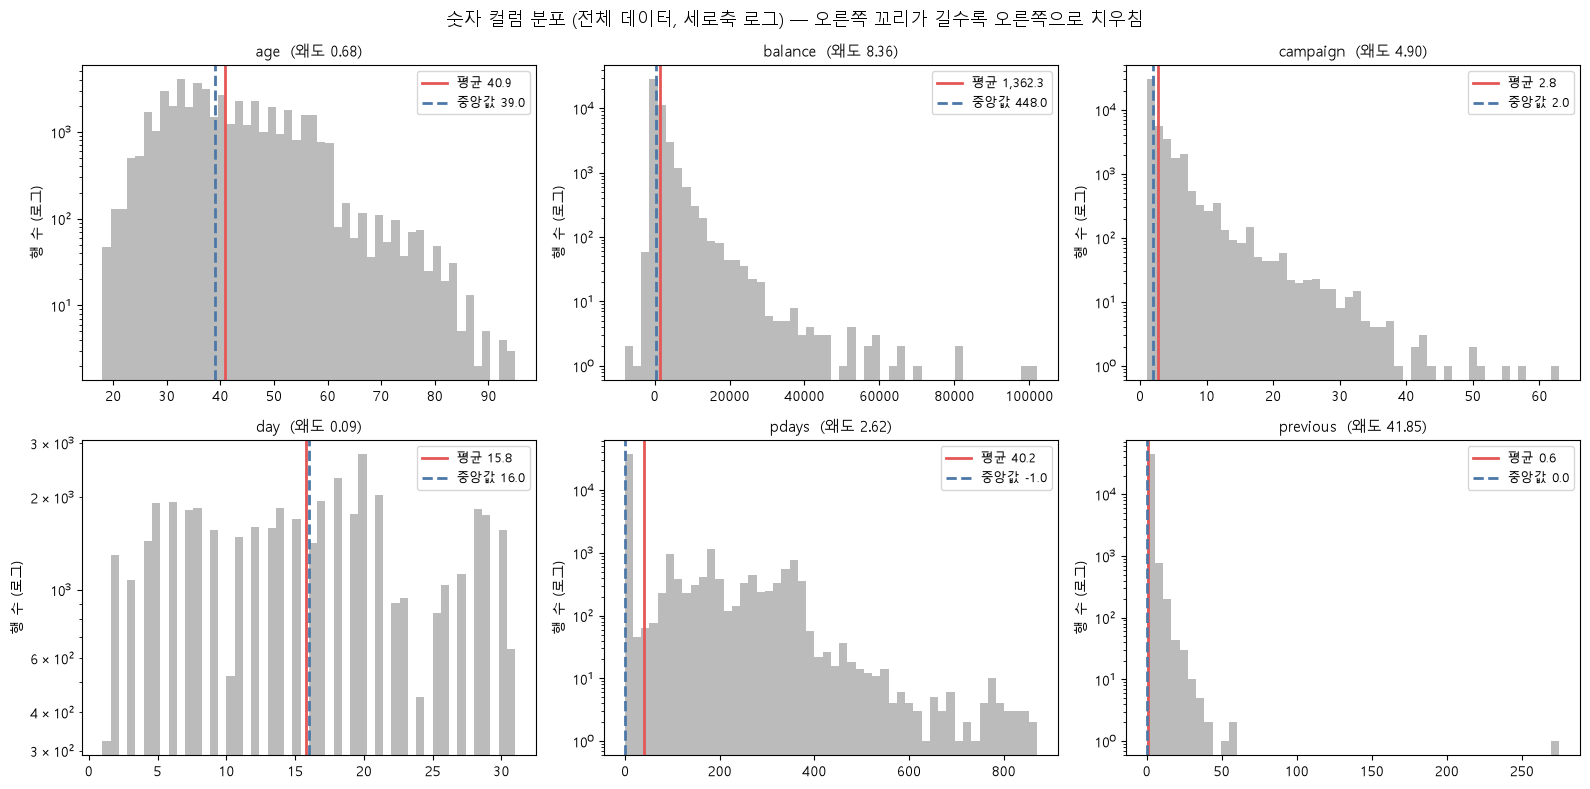

In [77]:
# 2-3-1. 숫자 컬럼의 왜도 (원본 데이터)
skew_cols = ['age', 'balance', 'campaign', 'day', 'pdays', 'previous']

rows = []
for c in skew_cols:
    s = df[c]
    rows.append({'컬럼': c, '왜도': s.skew(), '평균': s.mean(), '중앙값': s.median(),
                 '왜도 (최댓값 1행 제외)': s.drop(s.idxmax()).skew()})
display(pd.DataFrame(rows).set_index('컬럼').round(2).sort_values('왜도', ascending=False))
# 2-3-1. 숫자 컬럼 분포 (전체 데이터, 세로축 로그 스케일)
skew_cols = ['age', 'balance', 'campaign', 'day', 'pdays', 'previous']



fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), skew_cols):
    s = df[c]
    ax.hist(s, bins=50, color='#BBBBBB')
    ax.set_yscale('log')                                  # 세로축(행 수)만 로그 → 적은 막대도 보이게
    ax.axvline(s.mean(), color='#E45756', lw=2, label=f'평균 {s.mean():,.1f}')
    ax.axvline(s.median(), color='#4C78A8', lw=2, ls='--', label=f'중앙값 {s.median():,.1f}')
    ax.set_title(f'{c}  (왜도 {s.skew():.2f})', fontsize=11)
    ax.set_ylabel('행 수 (로그)')
    ax.legend(fontsize=9)
fig.suptitle('숫자 컬럼 분포 (전체 데이터, 세로축 로그) — 오른쪽 꼬리가 길수록 오른쪽으로 치우침', fontsize=13)
plt.tight_layout(); plt.show()

> **왜도 해석**

 - **previous (41.85):** 왜도가 가장 크게 나타났습니다.  
 약 82%가 이전 연락 없음(0)에 몰려 있는 구조와, 입력 오류로 판단한 275 한 행의 영향이 함께 작용한 것으로 보입니다.  
 분포의 치우침보다는 구조적 결측의 영향이 클 것으로 판단해 결측치 기준으로 따로 다뤘습니다.

 - **balance (8.36):** 오른쪽으로 크게 치우친 분포로 나타났습니다.  
 평균(1,362)이 중앙값(448)의 약 3배로, 소수의 높은 잔고가 평균을 끌어올린 것으로 보입니다.

 - **campaign (4.90):** 오른쪽으로 크게 치우친 분포로 나타났습니다.  
 대부분 1~3회 연락했지만 최대 63회까지 있어, 평균(2.76)이 중앙값(2)보다 크게 나타난 것으로 보입니다.

 - **pdays (2.62):** previous와 마찬가지로 약 82%가 이전 연락 없음(-1)에 몰려 있어, 이 구조가 왜도에 영향을 준 것으로 보입니다.  
 중앙값이 -1로 나타난 점도 이와 관련이 있는 것으로 보여 결측치 기준으로 따로 다뤘습니다.

 - **age (0.68):** 약간 오른쪽으로 치우쳤지만 평균(40.9)과 중앙값(39)이 비슷해 비교적 대칭에 가까운 것으로 보입니다.

 - **day (0.09):** 평균(15.8)과 중앙값(16)이 거의 같아 대칭에 가까운 것으로 보입니다.

 **결론:** balance, campaign처럼 크게 치우친 컬럼에서는 평균과 표준편차가 극단값의 영향을 받아 Z-score 기준이 흔들릴 가능성이 있다고 판단하여  
 사분위수를 쓰는 **IQR로 이상치를 탐지**했습니다.

>  **이상치 탐지 방법: IQR**  
기준 : (1.5 × IQR 규칙: Q1 − 1.5×IQR 미만 또는 Q3 + 1.5×IQR 초과)

 - balance(왜도 8.36), campaign(왜도 4.90)처럼 분포가 한쪽으로 크게 치우쳐있는 형태입니다.   
 평균과 표준편차를 쓰는 Z-score보다 사분위수를 써서 극단값에 덜 흔들리는 IQR로 탐지했습니다.

 - 탐지는 모든 숫자 컬럼에 같은 기준을 적용하고, 처리는 값이 실제로 가능한지에 따라 컬럼별로 정했습니다.  
 IQR 밖의 값이라도 실제로 있을 수 있는 값(고령, 큰 잔고, 많은 연락 횟수)들은 유지했습니다.

 - pdays · previous는 약 82%가 이전 연락 없음(-1, 0)이라 IQR = 0이 되어, 이력이 있는 행 전체가 이상치로 잡힙니다.  
 이는 이상치가 아니라 구조적 결측이므로 IQR 대신 결측치 기준으로 판단했습니다.

 
 - 로지스틱회귀는 값의 크기가 계수 추정에 직접 반영되어 극단값의 영향을 받을 수 있으므로, Train 기준 1%·99% 값으로 캡했습니다.  
 (캡 기준은 Train에서만 계산해 Test 정보가 들어가지 않도록 했습니다.)  
트리 모델(LightGBM 등)은 값의 크기 자체보다 값의 순서를 기준으로 분할하므로 별도로 처리하지 않았습니다. 

,최솟값,최댓값,IQR 이상치,IQR 비율(%),Z>3 건수
변수,,,,,
age,18,95,487,1.08,381
balance,-8019,102127,4729,10.46,745
day,1,31,0,0.00,0
duration,0,4918,3235,7.16,963
campaign,1,63,3064,6.78,840
pdays,-1,871,8257,18.26,1723
previous,0,275,8257,18.26,582


balance 음수: 3766 / campaign 10회 이상: 1462
previous 상위 5개: [41, 51, 55, 58, 275]


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
29182,40,management,married,tertiary,no,543,yes,no,cellular,2,feb,349,2,262,275,other,no


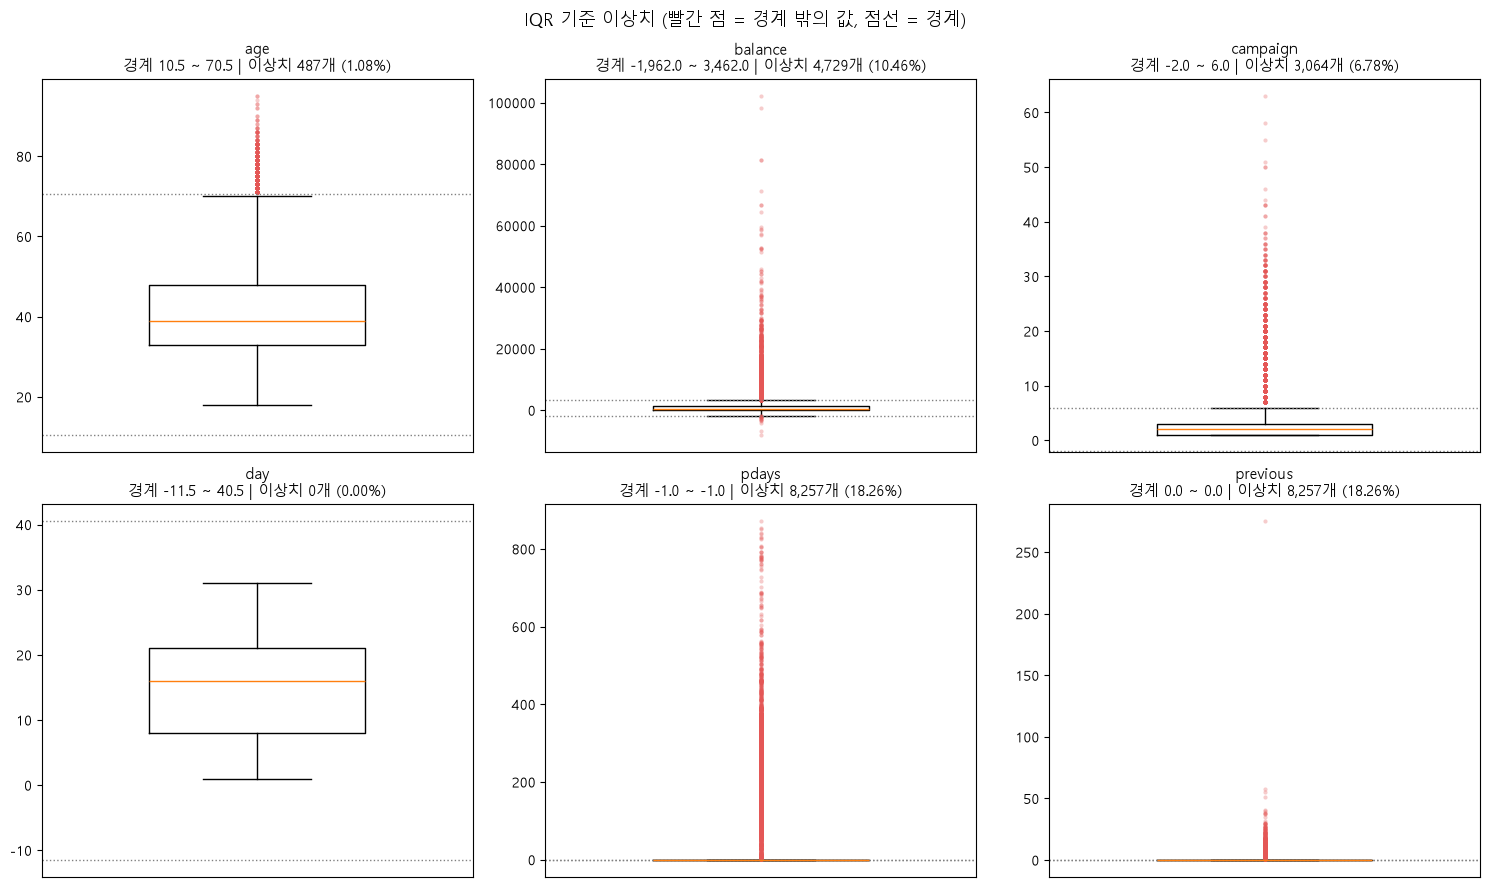

In [73]:
def iqr_count(s):
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return ((s < lo) | (s > hi)).sum(), lo, hi

rows = []
for c in num_cols_raw:
    n, lo, hi = iqr_count(df[c])
    rows.append({'변수': c, '최솟값': df[c].min(), '최댓값': df[c].max(),
                 'IQR 이상치': n, 'IQR 비율(%)': round(n / len(df) * 100, 2),
                 'Z>3 건수': int((((df[c] - df[c].mean()) / df[c].std()).abs() > 3).sum())})
display(pd.DataFrame(rows).set_index('변수'))

print('balance 음수:', (df['balance'] < 0).sum(), '/ campaign 10회 이상:', (df['campaign'] >= 10).sum())
print('previous 상위 5개:', sorted(df['previous'])[-5:])
display(df[df['previous'] == 275])

# 2-3-3. IQR 이상치 시각화: 상자그림 (수염 끝 = Q1 - 1.5×IQR, Q3 + 1.5×IQR)
iqr_cols = ['age', 'balance', 'campaign', 'day', 'pdays', 'previous']

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, c in zip(axes.ravel(), iqr_cols):
    s = df[c]
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n_out = ((s < lo) | (s > hi)).sum()

    ax.boxplot(s, whis=1.5, widths=0.5,
               flierprops=dict(marker='o', markersize=3, markerfacecolor='#E45756', markeredgecolor='none', alpha=0.3))
    ax.axhline(lo, color='gray', ls=':', lw=1); ax.axhline(hi, color='gray', ls=':', lw=1)
    ax.set_xticks([])
    ax.set_title(f'{c}\n경계 {lo:,.1f} ~ {hi:,.1f} | 이상치 {n_out:,}개 ({n_out / len(s):.2%})', fontsize=11)
fig.suptitle('IQR 기준 이상치 (빨간 점 = 경계 밖의 값, 점선 = 경계)', fontsize=13)
plt.tight_layout(); plt.show()

**이상치 탐지 결과**

- **age :** 70.5세를 넘는 487건(1.08%)이 IQR 이상치로 잡혔으나, 최댓값이 95세이고 실제로 존재할 수 있는 값이므로 유지했습니다.

- **balance :** 4,729건(10.46%)으로 이상치 비율이 가장 높게 나타났습니다.  
상자그림에서도 상자가 0 근처에 납작하게 붙어 있고 위로 10만까지 점이 길게 이어지는 모습이 보입니다.  
음수 잔고도 3,766건 있었지만, 마이너스 통장처럼 실제로 가능한 값으로 보여 유지했습니다.  

- **campaign :**은 6회를 넘는 3,064건(6.78%)이 이상치로 잡혔고, 10회 이상 연락한 경우도 1,462건 있었습니다.  
같은 고객에게 여러 번 연락하는 것은 실제로 가능한 상황으로 보여 유지했습니다.

- **day :** 1~31일 범위 안에 있어 이상치가 나타나지 않았습니다.

- **pdays와 previous :** 둘 다 8,257건(18.26%)이 이상치로 잡혔습니다.  
약 82%가 이전 연락 없음(-1, 0)에 몰려 있어 IQR이 0이 되었고, 그 결과 이전 연락 이력이 있는 행 전체가 이상치로 분류된 것으로 보입니다.  
상자그림에서 상자가 선 하나로 납작하게 보이는 형태를 띄고 있으며, 이는 이상치라기보다 구조적 결측의 영향으로 판단했습니다.  
다만 **previous = 275** 한 행은 예외로 보았습니다.  
previous 상위 값이 41, 51, 55, 58로 이어지다 275로 떨어져 있고, 상자그림에서도 이 점 하나만 따로 떨어져 있습니다.  
이전 캠페인에서 275번 연락했다는 것은 현실적으로 어렵다고 보아 입력 오류로 판단하고 삭제했습니다.  

- **duration :** 3,235건(7.16%)이 이상치로 잡혔지만, 데이터 누수 때문에 모델에서 제외하므로 이상치 처리 대상에서 뺐습니다.

> **결과 요약**

 | 컬럼 | 범위 | IQR 이상치 | 판단 |
 | --- | --- | --- | --- |
 | age | 18 ~ 95 | 1.08% | 실제 가능 → 유지 |
 | balance | -8,019 ~ 102,127 | 10.46% | 실제 가능 (음수 3,766건) → **로지스틱회귀만 1%·99% 캡** |
 | campaign | 1 ~ 63 | 6.78% | 실제 가능 → **로지스틱회귀만 1%·99% 캡** |
 | pdays / previous | | 18.26% | 구조적 결측(-1, 0) 때문. 이상치 처리 안 함 |
 | previous = **275** | 1행 | | 다음으로 큰 값은 58. → **입력 오류로 판단 → 삭제** |

## 3. 데이터 정제 (분할 전)

행마다 **규칙으로만** 바꾸는 처리라서 분할 전에 진행해도 누수가 없습니다.

| 처리 | 이유 |
| --- | --- |
| pdays -1 → 0 | -1은 일수가 아니라 "이전 연락 없음". 원래 pdays = 0인 행이 없어 실제 값과 겹치지 않음 |
| poutcome unknown → `no_prev_campaign` (previous = 0인 행만) | 이전 캠페인이 없어 결과가 존재하지 않음 |
| previous = 275 삭제 | 입력 오류 |
| `call_date` 추가 | 파생변수 (하루 통화량 · 누적 가입률)을 만들기 위한 날짜 |

In [78]:
df_clean = df.copy()

no_prev = df_clean['previous'] == 0
df_clean.loc[no_prev, 'pdays'] = 0
df_clean.loc[no_prev, 'poutcome'] = 'no_prev_campaign'
df_clean = df_clean[df_clean['previous'] != 275].reset_index(drop=True)

# 날짜 만들기: 행이 시간순이라는 가정에서, 월이 크게 줄어드는 지점(12월 → 1월)마다 연도 +1 (시작 2008년)
months = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
month_num = df_clean['month'].map({m: i for i, m in enumerate(months, start=1)})
year = 2008 + (month_num.diff().fillna(0) < -6).cumsum()
df_clean['call_date'] = (year.astype(str) + '-' + month_num.astype(str).str.zfill(2)
                         + '-' + df_clean['day'].astype(str).str.zfill(2))
# 중복 16건 삭제
df_clean = df_clean[df_clean['previous'] != 275].reset_index(drop=True)
df_clean = df_clean.drop_duplicates(subset=key_cols + ['y'], keep='first').reset_index(drop=True)   # 추가: duration 제외 중복 16건 삭제

print('정제 후:', df_clean.shape)
display(df_clean['poutcome'].value_counts().to_frame('건수'))

정제 후: (45194, 18)


,건수
poutcome,
no_prev_campaign,36938
failure,4901
other,1839
success,1511
unknown,5


## 4. EDA

y와의 관계를 보는 분석은 **Train 데이터로만** 합니다 (5장에서 나누는 것과 같은 분할).  

변수별 가입 여부와의 연관성을 봅니다.  
가입 여부(y)는 yes/no 두 값으로 이루어진 이진 변수이므로, 비교하는 변수의 종류에 따라 다른 지표를 사용했습니다.

- **범주형 변수 → Cramér's V:** 1에 가까울 수록 연관성이 강합니다, job처럼 범주가 여러 개인 변수도 같은 기준으로 비교할 수 있어 사용했습니다.

- **수치형 변수 → 피어슨 상관계수(절댓값):** 방향(+/−)보다 연관성의 크기를 보기 위해 절댓값 사용, 절대값을 사용하면 1에 가까울수록 연관성이 강합니다.  

In [79]:
X_all = df_clean.drop(columns=['y', 'duration'])
y_all = (df_clean['y'] == 'yes').astype(int)
X_tr_eda, _, y_tr_eda, _ = train_test_split(X_all, y_all, test_size=0.2,
                                            stratify=y_all, random_state=RANDOM_STATE)
eda = X_tr_eda.assign(y=y_tr_eda)

# 4-1. 각 컬럼과 y의 관련성 (범주형: 크라메르 V, 수치형: 점이연 상관계수 절댓값)
rows = []
for c in [c for c in X_tr_eda.columns if c != 'call_date']:
    if pd.api.types.is_numeric_dtype(X_tr_eda[c]):
        rows.append({'변수': c, '종류': '수치형', '관련성': abs(X_tr_eda[c].corr(y_tr_eda))})
    else:
        tab = pd.crosstab(X_tr_eda[c], y_tr_eda)
        v = np.sqrt(chi2_contingency(tab)[0] / (tab.values.sum() * (min(tab.shape) - 1)))
        rows.append({'변수': c, '종류': '범주형', '관련성': v})
display(pd.DataFrame(rows).set_index('변수').sort_values('관련성', ascending=False).round(3))

# 4-2. 그룹별 가입률
def rate(col):
    return eda.groupby(col, observed=True)['y'].agg(행수='size', 가입률='mean').round(3)
display(rate('poutcome'))
display(rate(pd.cut(eda['age'], [0, 29, 39, 49, 59, 100], labels=['~29', '30대', '40대', '50대', '60+'])))
display(rate('job').sort_values('가입률'))

,종류,관련성
변수,,
poutcome,범주형,0.311
month,범주형,0.256
contact,범주형,0.149
housing,범주형,0.140
job,범주형,0.137
previous,수치형,0.114
pdays,수치형,0.097
campaign,수치형,0.072
education,범주형,0.071


,행수,가입률
poutcome,,
failure,3916,0.119
no_prev_campaign,29545,0.093
other,1478,0.164
success,1211,0.647
unknown,5,0.400


,행수,가입률
age,,
~29,4213,0.179
30대,14523,0.106
40대,9291,0.092
50대,6712,0.091
60+,1416,0.338


,행수,가입률
job,,
blue-collar,7869,0.073
housemaid,1020,0.080
entrepreneur,1172,0.084
services,3311,0.091
technician,6039,0.110
self-employed,1249,0.117
unknown,239,0.121
admin.,4129,0.124
management,7542,0.138


**변수별 가입 여부와의 연관성**

연관성이 가장 크게 나타난 변수는 **poutcome(0.311)**이며, month(0.256), contact(0.149), housing(0.140), job(0.137) 순입니다.  
이전 캠페인 결과와 연락한 시기가 가입 여부와 비교적 관련이 높은 것으로 보입니다.

수치형 변수는 모두 0.12 미만이었습니다. previous(0.114)가 가장 높았고, age(0.022)는 전체 변수 중 가장 낮았습니다.  
다만 피어슨 상관계수는 직선 관계만 측정하므로, 비선형 관계는 낮게 나올 수 있습니다.  
따라서 수치가 낮다고 해서 가입 여부와 관련이 없다고 단정하기는 어려우며, 구간별 가입률로 확인합니다.

가장 높은 poutcome도 0.311로 중간 수준에 그쳐, 변수 하나만으로 가입 여부를 설명하기는 어려운 것으로 보입니다.  
이에 여러 변수를 함께 고려하는 모델이 필요하다고 판단했습니다.  

**그룹별 가입률** (Train 전체 가입률 약 11.7%)

**poutcome:** 이전 캠페인에서 가입한 고객(success)의 가입률이 64.7%로, 전체 평균의 약 5.5배로 나타났습니다.  
반면 이전 캠페인 이력이 없는 고객(no_prev_campaign)은 9.3%로 평균보다 낮았으며, 이 그룹이 Train의 약 82%(29,545행)를 차지합니다.  
unknown은 40.0%이지만 5행으로 표본이 매우 적어 해석에 주의가 필요합니다.

**나이대:** 60세 이상(33.8%)과 29세 이하(17.9%)의 가입률이 평균보다 높았고, 30~50대는 9~11% 수준으로 평균보다 낮게 나타났습니다.  
양 끝 나이대가 높고 가운데가 낮은 모습으로, 나이와 가입률이 직선 관계가 아닐 가능성이 있습니다.  

**job:** 학생(29.2%), 은퇴자(22.9%), 무직(15.1%)의 가입률이 높았고, 블루칼라(7.3%), 가사도우미(8.0%), 자영업(8.4%)은 낮게 나타났습니다.  
학생과 은퇴자는 나이대의 양 끝과 겹치는 직업이라, 나이대에서 본 패턴과 관련이 있을 것으로 보입니다.  

> **상관계수가 낮게 나온 수치형 변수의 구간별 가입률 확인**

age(0.022), day(0.028), balance(0.059), campaign(0.072)은 피어슨 상관계수가 낮게 나타났으나 피어슨 상관계수는 직선 관계만 측정하므로,  
직선이 아닌 관계가 있다면 실제보다 낮게 나올 수 있어 그래프로 확인합니다.  
나이대별 가입률도 양 끝에서 높고 가운데에서 낮게 나타나, 직선이 아닌 비선형 관계일 가능성이 있습니다.

따라서 상관계수만으로 이 변수들이 가입 여부와 관련이 없다고 판단하지 않기 위해,  
값을 구간으로 나누어 구간별 가입률이 어떤 모양으로 변하는지 확인합니다.

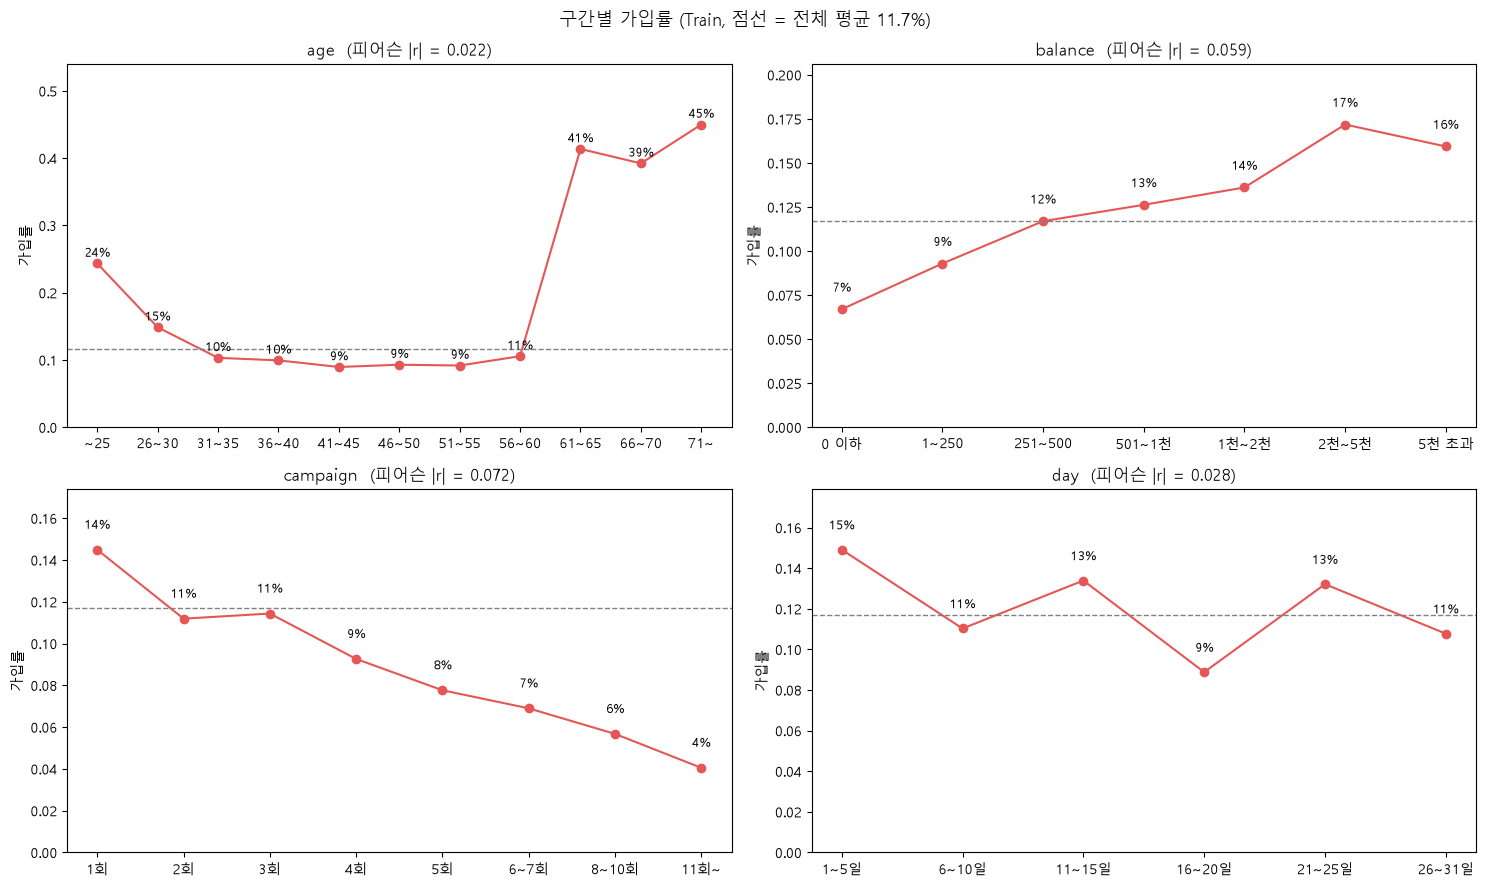

In [80]:
# 4-3. 상관계수가 낮게 나온 수치형 변수: 구간별 가입률로 보기 (Train)
overall = eda['y'].mean()
bins = {   # 컬럼: (구간 경계, 구간 이름)
    'age':      ([17, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 100],
                 ['~25', '26~30', '31~35', '36~40', '41~45', '46~50', '51~55', '56~60', '61~65', '66~70', '71~']),
    'balance':  ([-1e9, 0, 250, 500, 1000, 2000, 5000, 1e9],
                 ['0 이하', '1~250', '251~500', '501~1천', '1천~2천', '2천~5천', '5천 초과']),
    'campaign': ([0, 1, 2, 3, 4, 5, 7, 10, 100],
                 ['1회', '2회', '3회', '4회', '5회', '6~7회', '8~10회', '11회~']),
    'day':      ([0, 5, 10, 15, 20, 25, 31],
                 ['1~5일', '6~10일', '11~15일', '16~20일', '21~25일', '26~31일'])}

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, (c, (b, labels)) in zip(axes.ravel(), bins.items()):
    r = eda.groupby(pd.cut(eda[c], b, labels=labels), observed=True)['y'].agg(['size', 'mean'])
    ax.plot(r.index.astype(str), r['mean'], marker='o', color='#E45756')
    ax.axhline(overall, color='gray', ls='--', lw=1)
    for i, v in enumerate(r['mean']):
        ax.text(i, v + 0.01, f'{v:.0%}', ha='center', fontsize=9)
    corr = abs(eda[c].corr(eda['y']))
    ax.set_title(f'{c}  (피어슨 |r| = {corr:.3f})')
    ax.set_ylabel('가입률'); ax.set_ylim(0, r['mean'].max() * 1.2)
fig.suptitle(f'구간별 가입률 (Train, 점선 = 전체 평균 {overall:.1%})', fontsize=13)
plt.tight_layout(); plt.show()

**구간별 가입률 해석**

- **age:** 25세 이하는 24%, 31~60세 구간은 9~11%, 61세 이상은 39~45%로 나타났습니다.  
양 끝 구간의 가입률이 평균(11.7%)보다 상대적으로 크고 가운데 구간은 평균 근처에 머무는 U자형에 가까운 모습으로,  
-> 직선 관계가 아니어서 피어슨 상관계수(0.022)가 작게 나온 것으로 보입니다.

- **balance:** 잔고가 0 이하인 구간은 7%, 2천~5천 구간은 17%로 나타나, 잔고가 많은 구간일수록 가입률이 커지는 경향을 보였습니다.  
한 방향의 경향이 보이는데도 상관계수(0.059)가 작은 것은, 잔고 분포가 크게 치우쳐 있어 소수의 극단값이 상관계수에 영향을 준 것으로 보입니다.

- **campaign:** 1회는 14%, 11회 이상은 4%로 나타나, 연락 횟수가 많은 구간일수록 가입률이 작아지는 경향을 보였습니다.  
balance와 마찬가지로 한 방향의 경향이 보이지만, 치우친 분포의 영향으로 상관계수(0.072)는 작게 나온 것으로 보입니다.

- **day:** 구간별 가입률이 9~15% 사이에서 나타났으며, 일정한 방향의 경향은 보이지 않았습니다.  
상관계수(0.028)와 마찬가지로 가입 여부와의 관련이 약한 것으로 보입니다.

**정리:** age, balance, campaign은 상관계수가 작게 나왔지만, 구간별로 보면 가입률이 달라지는 패턴이 나타났습니다.  
따라서 상관계수만으로 변수를 제외하지 않고 모델에 포함했으며, 직선이 아닌 관계도 학습할 수 있는 트리 기반 모델을 함께 비교하기로 했습니다.

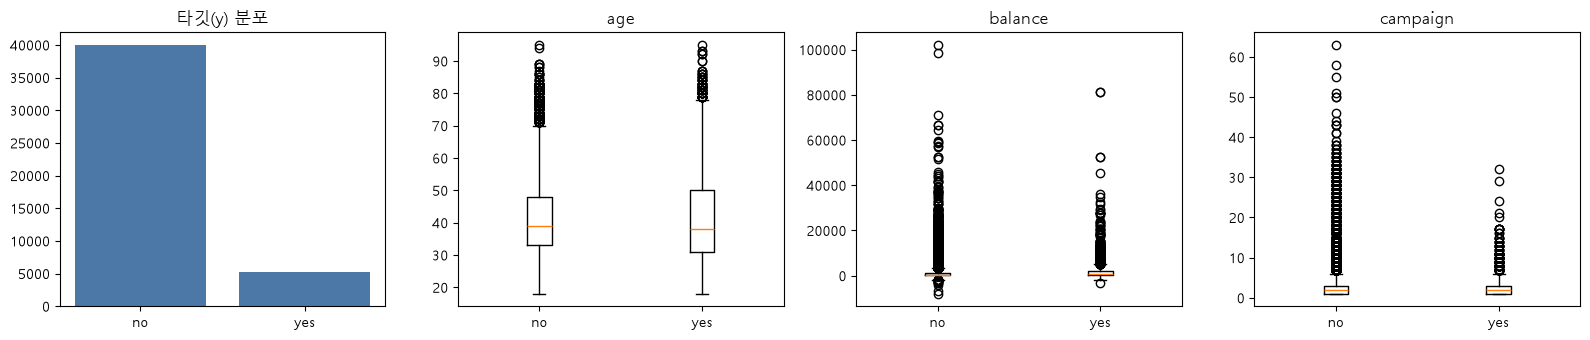

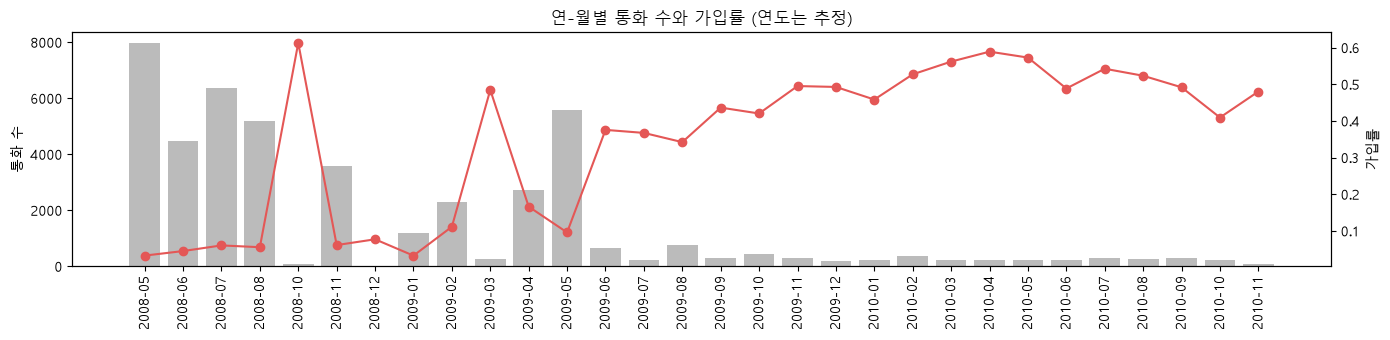

In [50]:
# 4-3. 그림: 타깃 분포, 수치형 분포(가입 여부별)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
cnt = df['y'].value_counts()
axes[0].bar(cnt.index, cnt.values, color='#4C78A8'); axes[0].set_title('타깃(y) 분포')
for ax, col in zip(axes[1:], ['age', 'balance', 'campaign']):
    ax.boxplot([df.loc[df['y'] == v, col] for v in ['no', 'yes']], tick_labels=['no', 'yes'])
    ax.set_title(col)
plt.tight_layout(); plt.show()

# 4-4. 시간에 따른 변화: 월(연-월)별 통화 수와 가입률
ym = df_clean['call_date'].str[:7]
trend = df_clean.assign(ym=ym, yy=y_all).groupby('ym')['yy'].agg(['size', 'mean'])
fig, ax1 = plt.subplots(figsize=(14, 3.5))
ax1.bar(trend.index, trend['size'], color='#BBBBBB'); ax1.set_ylabel('통화 수')
ax2 = ax1.twinx(); ax2.plot(trend.index, trend['mean'], color='#E45756', marker='o'); ax2.set_ylabel('가입률')
ax1.tick_params(axis='x', rotation=90); ax1.set_title('연-월별 통화 수와 가입률 (연도는 추정)')
plt.tight_layout(); plt.show()

> **결과 요약**
> - **y와 관련이 큰 변수:** poutcome(0.311) > month(0.257) > contact(0.150) > housing(0.139) > job(0.138)
> - **이전 캠페인 가입 고객**의 가입률은 64.7%로, 이력 없는 고객(9.2%)의 약 7배
> - **나이는 U자형:** 60세 이상 34.0%, 29세 이하 17.5%, 40~50대 약 9%
> - **시간에 따른 변화:** 2008년 하루 평균 227통 · 가입률 5.1% → 2010년 12통 · 51.6%. 대량 통화에서 선별 통화로 바뀐 것으로 보임 (**추정**)

## 5. Train / Test 분할

- `duration` 제외 (통화가 끝나야 알 수 있는 값 → **누수**)
- Train 80% / Test 20%, `stratify=y`로 가입률을 같게 맞춤
- `call_date`는 그대로 모델에 들어가지 않고, 6장의 변환기가 통화량 · 누적 가입률로 바꿀 때만 사용

In [51]:
X = df_clean.drop(columns=['y', 'duration'])
y = (df_clean['y'] == 'yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

display(pd.DataFrame({'Train 건수': y_train.value_counts(), 'Train 비율': y_train.value_counts(normalize=True).round(3),
                      'Test 건수': y_test.value_counts(), 'Test 비율': y_test.value_counts(normalize=True).round(3)})
          .rename(index={0: 'no (0)', 1: 'yes (1)'}))

neg_pos = (y_train == 0).sum() / (y_train == 1).sum()       # no ÷ yes ≈ 7.55
print('Train:', X_train.shape, '/ Test:', X_test.shape, '/ no : yes =', round(neg_pos, 2), ': 1')

,Train 건수,Train 비율,Test 건수,Test 비율
y,,,,
no (0),31924,0.883,7981,0.883
yes (1),4231,0.117,1058,0.117


Train: (36155, 16) / Test: (9039, 16) / no : yes = 7.55 : 1


> **결과 요약:** Train 36,168행(yes 4,231) / Test 9,042행(yes 1,058), 두 데이터 모두 가입률 11.7%

## 6. 전처리기 · 평가 함수

모든 기준값(범주 목록, 분위수, 평균, 표준편차, 날짜별 통화 수, 누적 가입률)은 **Pipeline 안에서 Train(학습 fold)으로만** 계산

| 변환기 | 하는 일 |
| --- | --- |
| `QuantileCapper` | balance, campaign을 학습 데이터의 1%·99% 분위수로 자름 (로지스틱회귀용) |
| `CallsPerDay` | 학습 데이터에서 날짜별 통화 **비율**을 셈 → **하루 통화량** |
| `CumRate` | 학습 데이터에서 첫 통화일 ~ **전날까지**의 가입률 → **누적 가입률** (오늘 행은 제외) |

In [52]:
class QuantileCapper(BaseEstimator, TransformerMixin):
    # 학습 데이터의 하위·상위 분위수로 값을 자름
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_, self.hi_ = X.quantile(self.lower), X.quantile(self.upper)
        return self
    def transform(self, X):
        return pd.DataFrame(X).clip(self.lo_, self.hi_, axis=1)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

class CallsPerDay(BaseEstimator, TransformerMixin):
    # 학습 데이터의 날짜별 통화 비율 (학습 데이터 크기와 상관없이 같은 기준이 되도록 '비율'로 계산)
    def fit(self, X, y=None):
        dates = pd.DataFrame(X).iloc[:, 0]
        self.share_ = dates.value_counts() / len(dates)
        return self
    def transform(self, X):
        dates = pd.DataFrame(X).iloc[:, 0]
        return dates.map(self.share_).fillna(0).to_frame('calls_per_day').values
    def get_feature_names_out(self, input_features=None):
        return np.array(['calls_per_day'], dtype=object)

class CumRate(BaseEstimator, TransformerMixin):
    # 첫 통화일 ~ 전날까지 학습 행의 가입률 (오늘 제외 → 자기 정답이 들어가지 않음)
    def fit(self, X, y=None):
        d = pd.DataFrame({'d': pd.DataFrame(X).iloc[:, 0].values, 'y': np.asarray(y)})
        g = d.groupby('d')['y'].agg(['sum', 'count']).sort_index()
        self.dates_ = g.index.values
        self.cum_sum_ = g['sum'].cumsum().values
        self.cum_cnt_ = g['count'].cumsum().values
        return self
    def transform(self, X):
        d = pd.DataFrame(X).iloc[:, 0].values
        k = np.searchsorted(self.dates_, d, side='left')      # 오늘보다 앞선 날짜 개수
        out = np.full(len(d), np.nan)                         # 이전 기록이 없으면 NaN
        ok = k > 0
        out[ok] = self.cum_sum_[k[ok] - 1] / self.cum_cnt_[k[ok] - 1]
        return out.reshape(-1, 1)
    def get_feature_names_out(self, input_features=None):
        return np.array(['cum_rate'], dtype=object)

In [53]:
cat_cols  = X_train.select_dtypes(exclude='number').columns.drop('call_date').tolist()   # 범주형 9개
num_cols  = X_train.select_dtypes(include='number').columns.tolist()                     # 수치형 6개
cap_cols  = ['balance', 'campaign']
other_num = [c for c in num_cols if c not in cap_cols]

def ohe():
    return OneHotEncoder(handle_unknown='ignore', sparse_output=False)

def calls_pipe():
    return Pipeline([('count', CallsPerDay()), ('scale', StandardScaler())])

def make_prep(kind, calls=False, cum=False, cum_impute=False):
    # kind='linear': 원핫 + 캡 + 표준화 (로지스틱회귀) / kind='tree': 원핫 + 표준화 (나무 모델, SMOTE 거리 계산용)
    if kind == 'linear':
        tf = [('cat', ohe(), cat_cols),
              ('cap', Pipeline([('cap', QuantileCapper()), ('scale', StandardScaler())]), cap_cols),
              ('num', StandardScaler(), other_num)]
    else:
        tf = [('cat', ohe(), cat_cols), ('num', StandardScaler(), num_cols)]
    if calls:
        tf.append(('calls', calls_pipe(), ['call_date']))
    if cum:
        steps = [('cum', CumRate())]
        if cum_impute:                                   # NaN을 못 받는 모델용 (학습 fold 평균으로 채움)
            steps.append(('imp', SimpleImputer(strategy='mean')))
            if kind == 'linear':
                steps.append(('scale', StandardScaler()))
        tf.append(('cum', Pipeline(steps) if len(steps) > 1 else CumRate(), ['call_date']))
    return ColumnTransformer(tf)                         # 나머지 컬럼(call_date 원본)은 버림

for name, p in [('원본 (linear)', make_prep('linear')), ('원본 (tree)', make_prep('tree')),
                ('+ 통화량', make_prep('tree', calls=True)), ('+ 통화량 + 누적', make_prep('tree', calls=True, cum=True))]:
    n = clone(p).fit(X_train, y_train).get_feature_names_out()
    print(f'{name:16s} 변환 후 컬럼 {len(n)}개 / 마지막: {n[-1]}')

원본 (linear)      변환 후 컬럼 51개 / 마지막: num__previous
원본 (tree)        변환 후 컬럼 51개 / 마지막: num__previous
+ 통화량            변환 후 컬럼 52개 / 마지막: calls__calls_per_day
+ 통화량 + 누적       변환 후 컬럼 53개 / 마지막: cum__cum_rate


In [54]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'PR-AUC': 'average_precision', 'Accuracy': 'accuracy', 'F1': 'f1',
           'Precision': 'precision', 'Recall': 'recall'}
METRICS = ['PR-AUC', 'Accuracy', 'F1', 'Precision', 'Recall']

def cv_row(model_name, method, pipe, n_jobs=-1, fit_params=None):
    # Train 5-fold 평균 한 줄
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=n_jobs, params=fit_params)
    row = {'모델': model_name, '방법': method}
    row.update({k: s[f'test_{k}'].mean() for k in METRICS})
    row['학습시간(초)'] = s['fit_time'].mean()
    row['PR-AUC 표준편차'] = s['test_PR-AUC'].std()
    return row

def fold_table(name, pipe):
    # fold별 결과 + 평균 + 표준편차 (Train PR-AUC로 과적합도 확인)
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=1)
    t = pd.DataFrame({'Fold': [f'Fold {i+1}' for i in range(5)],
                      **{k: res[f'test_{k}'] for k in ['PR-AUC', 'Precision', 'Recall', 'F1', 'Accuracy']},
                      'Train PR-AUC': res['train_PR-AUC'], '학습시간(초)': res['fit_time']})
    mean = t.drop(columns='Fold').mean().to_frame().T; mean.insert(0, 'Fold', '평균')
    std  = t.drop(columns='Fold').std().to_frame().T;  std.insert(0, 'Fold', '표준편차')
    print(f'===== {name} =====')
    display(pd.concat([t, mean, std], ignore_index=True).round(4))
    return res

def show_search(name, search, top=5):
    # 탐색 결과 상위 N개 (PR-AUC 순위)
    res = pd.DataFrame(search.cv_results_)
    params = [c for c in res.columns if c.startswith('param_')]
    out = (res.sort_values('rank_test_PR-AUC')[params + [f'mean_test_{k}' for k in METRICS] + ['std_test_PR-AUC', 'mean_fit_time']]
              .rename(columns={**{f'mean_test_{k}': k for k in METRICS},
                               'std_test_PR-AUC': 'PR-AUC 표준편차', 'mean_fit_time': '학습시간(초)'}))
    display(out.head(top).round(4))
    print(f'{name} 최적 설정:', search.best_params_)

def with_model(prep, model):
    return Pipeline([('prep', prep), ('model', model)])

## 7. 베이스라인 (기본 설정, 불균형 처리 없음)

In [55]:
base_models = {'LogisticRegression': (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), 'linear'),
               'DecisionTree':       (DecisionTreeClassifier(random_state=RANDOM_STATE), 'tree')}

display(pd.DataFrame([cv_row(n, 'Baseline', with_model(make_prep(k), clone(m)))
                      for n, (m, k) in base_models.items()]).round(3))

# 과적합 확인: Train 점수 vs 검증 점수
for n, (m, k) in base_models.items():
    s = cross_validate(with_model(make_prep(k), clone(m)), X_train, y_train, cv=cv,
                       scoring='average_precision', return_train_score=True, n_jobs=-1)
    print(f"{n:20s} Train PR-AUC {s['train_score'].mean():.3f} / 검증 PR-AUC {s['test_score'].mean():.3f}")

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,LogisticRegression,Baseline,0.407,0.892,0.277,0.639,0.177,0.200,0.014
1,DecisionTree,Baseline,0.174,0.830,0.308,0.294,0.324,0.304,0.006


LogisticRegression   Train PR-AUC 0.410 / 검증 PR-AUC 0.407
DecisionTree         Train PR-AUC 1.000 / 검증 PR-AUC 0.174


> **결과 요약 (Train 5-fold 평균)**
>
> | 모델 | PR-AUC | F1 | Precision | Recall |
> | --- | --- | --- | --- | --- |
> | 로지스틱회귀 | 0.403 | 0.277 | 0.646 | 0.177 |
> | 의사결정나무 | 0.178 | 0.315 | 0.301 | 0.330 |
>
> - 로지스틱회귀: 과적합은 없지만 가입 고객의 82%를 놓치는 **낮은 Recall** 문제
> - 의사결정나무: Train PR-AUC 1.000 vs 검증 약 0.18로 **과적합** (기본값은 깊이 제한이 없음) → 9장에서 깊이 제한

## 8. 클래스 불균형 처리 비교

불균형 처리는 **Train(학습 fold)에만** 적용됩니다 (imblearn Pipeline).
비율 `1:3`은 처리 후 **yes : no = 1 : 3**이라는 뜻입니다. 가중치로는 yes 가중치 = 7.55 ÷ 3 = 2.52 (1:2 → 3.77, 1:1 → 7.55)입니다.

In [56]:
ratios = {'1:3': 1/3, '1:2': 1/2, '1:1': 1}

imb_rows = []
for n, (m, k) in base_models.items():
    imb_rows.append(cv_row(n, 'Baseline', with_model(make_prep(k), clone(m))))
    for label, r in ratios.items():
        imb_rows.append(cv_row(n, f'ClassWeight {label}',
                               with_model(make_prep(k), clone(m).set_params(class_weight={0: 1, 1: neg_pos * r}))))
        imb_rows.append(cv_row(n, f'RUS {label}',
                               ImbPipeline([('prep', make_prep(k)),
                                            ('sampler', RandomUnderSampler(sampling_strategy=r, random_state=RANDOM_STATE)),
                                            ('model', clone(m))])))
        imb_rows.append(cv_row(n, f'SMOTE {label}',
                               ImbPipeline([('prep', make_prep(k)),
                                            ('sampler', SMOTE(sampling_strategy=r, random_state=RANDOM_STATE)),
                                            ('model', clone(m))])))
display(pd.DataFrame(imb_rows).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,LogisticRegression,Baseline,0.407,0.892,0.277,0.639,0.177,0.171,0.014
1,LogisticRegression,ClassWeight 1:3,0.406,0.886,0.406,0.523,0.331,0.175,0.014
2,LogisticRegression,RUS 1:3,0.405,0.886,0.404,0.522,0.329,0.120,0.014
3,LogisticRegression,SMOTE 1:3,0.404,0.887,0.410,0.529,0.335,0.320,0.013
4,LogisticRegression,ClassWeight 1:2,0.405,0.875,0.437,0.462,0.414,0.177,0.014
5,LogisticRegression,RUS 1:2,0.404,0.875,0.440,0.463,0.419,0.106,0.014
6,LogisticRegression,SMOTE 1:2,0.404,0.874,0.438,0.458,0.419,0.316,0.013
7,LogisticRegression,ClassWeight 1:1,0.404,0.753,0.371,0.265,0.622,0.200,0.014
8,LogisticRegression,RUS 1:1,0.403,0.747,0.367,0.260,0.626,0.104,0.015
9,LogisticRegression,SMOTE 1:1,0.402,0.746,0.366,0.258,0.627,0.428,0.013


> **결과 요약**
> - 세 방법 모두 PR-AUC는 거의 로지스틱회귀 0.395 ~ 0.403, 의사결정나무 0.160 ~ 0.178.
> - Recall이 오르면 Precision은 떨어짐(트레이드오프) (로지스틱회귀 1:1: Recall 0.177 → 0.624, Precision 0.646 → 0.266).
> - RUS는 no 데이터를 많이 버리고, SMOTE는 결과가 비슷한데 느려서 **클래스 가중치**로 사용

## 9. 모델 비교 (원본 컬럼)

In [57]:
cw_opt_orig = [None, {0: 1, 1: 2.5}, {0: 1, 1: 4}, {0: 1, 1: 7.5}]

lr_search0 = GridSearchCV(with_model(make_prep('linear'), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
                          {'model__C': [0.01, 0.1, 1, 10], 'model__class_weight': cw_opt_orig},
                          cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1).fit(X_train, y_train)
show_search('로지스틱회귀 (원본)', lr_search0)

dt_search0 = GridSearchCV(with_model(make_prep('tree'), DecisionTreeClassifier(random_state=RANDOM_STATE)),
                          {'model__max_depth': [4, 6, 8, 10, 12, 15, 20], 'model__min_samples_leaf': [10, 30, 50, 100, 200],
                           'model__class_weight': cw_opt_orig},
                          cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1).fit(X_train, y_train)
show_search('의사결정나무 (원본)', dt_search0)

,param_model__C,param_model__class_weight,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
4,0.1,None,0.4072,0.8924,0.2678,0.6579,0.1685,0.0148,0.4072
8,1.0,None,0.4069,0.8920,0.2773,0.6392,0.1775,0.0144,0.2844
12,10.0,None,0.4069,0.8920,0.2787,0.6377,0.1787,0.0143,0.2853
5,0.1,"{0: 1, 1: 2.5}",0.4060,0.8869,0.4037,0.5267,0.3276,0.0143,0.3468
9,1.0,"{0: 1, 1: 2.5}",0.4057,0.8864,0.4040,0.5232,0.3292,0.0141,0.2844


로지스틱회귀 (원본) 최적 설정: {'model__C': 0.1, 'model__class_weight': None}


,param_model__class_weight,param_model__max_depth,param_model__min_samples_leaf,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
33,None,20,100,0.4129,0.8931,0.2944,0.6474,0.1907,0.0172,0.3086
97,"{0: 1, 1: 4}",15,50,0.4120,0.8501,0.4539,0.3956,0.5327,0.0127,0.2319
28,None,15,100,0.4116,0.8931,0.2944,0.6474,0.1907,0.0153,0.2897
102,"{0: 1, 1: 4}",20,50,0.4104,0.8440,0.4478,0.3824,0.5408,0.0144,0.2366
103,"{0: 1, 1: 4}",20,100,0.4102,0.8525,0.4404,0.3964,0.4961,0.0116,0.2145


의사결정나무 (원본) 최적 설정: {'model__class_weight': None, 'model__max_depth': 20, 'model__min_samples_leaf': 100}


In [58]:
more_models = {'RandomForest': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
               'LightGBM':     LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1)}
rows = []
for n, m in more_models.items():
    rows.append(cv_row(n, 'Baseline', with_model(make_prep('tree'), clone(m))))
    for label, r in ratios.items():
        rows.append(cv_row(n, f'ClassWeight {label}',
                           with_model(make_prep('tree'), clone(m).set_params(class_weight={0: 1, 1: neg_pos * r}))))
display(pd.DataFrame(rows).round(3))

if RUN_RF_SEARCH:
    rf_search0 = RandomizedSearchCV(
        with_model(make_prep('tree'), RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=RANDOM_STATE)),
        {'model__max_depth': [8, 12, 16, None], 'model__min_samples_leaf': [1, 5, 10, 20],
         'model__max_features': ['sqrt', 0.3, 0.5], 'model__class_weight': cw_opt_orig},
        n_iter=20, cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
    show_search('랜덤포레스트 (원본)', rf_search0)

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,RandomForest,Baseline,0.423,0.894,0.340,0.623,0.234,2.037,0.012
1,RandomForest,ClassWeight 1:3,0.416,0.887,0.397,0.527,0.319,2.243,0.014
2,RandomForest,ClassWeight 1:2,0.415,0.883,0.406,0.502,0.342,2.196,0.014
3,RandomForest,ClassWeight 1:1,0.412,0.878,0.432,0.476,0.396,2.015,0.011
4,LightGBM,Baseline,0.454,0.895,0.358,0.623,0.252,0.248,0.020
5,LightGBM,ClassWeight 1:3,0.450,0.882,0.467,0.497,0.441,0.255,0.020
6,LightGBM,ClassWeight 1:2,0.447,0.875,0.485,0.468,0.504,0.268,0.020
7,LightGBM,ClassWeight 1:1,0.445,0.824,0.451,0.355,0.616,0.242,0.020


> **결과 요약 (Train 5-fold)**
>
> | 모델 | 설정 | PR-AUC | F1 | Recall | 학습시간(초) |
> | --- | --- | --- | --- | --- | --- |
> | 로지스틱회귀 | Grid 최적 (C 0.1, 가중치 없음) | 0.4035 | 0.264 | 0.165 | 0.57 |
> | 의사결정나무 | Grid 최적 (깊이 20, 잎 100) | 0.4050 | 0.314 | 0.211 | 0.43 |
> | 랜덤포레스트 | 무작위 탐색 최적 (깊이 16, 잎 10) | 0.4441 | 0.306 | 0.199 | 14.10 |
> | **LightGBM** | **기본 + 가중치 1:2** | **0.444** | **0.483** | **0.505** | **0.31** |
>
> **LightGBM을 고른 이유:** 튜닝 없이도 튜닝한 랜덤포레스트와 PR-AUC가 같고, 가중치를 주면 F1 · Recall이 가장 높으며, 학습이 약 45배 빠릅니다.

## 10. 파생변수 ① 하루 통화량 (`calls_per_day`)

**가설:** 하루에 많이 거는 날은 넓은 고객층에 일괄로 거는 날이고, 적게 거는 날은 선별한 고객에게 거는 날이라 가입률이 다를 것이다.  
**하루 통화량 (`calls_per_day`)**: 학습 데이터에서 같은 날짜의 행 수 ÷ 각 폴드별 학습 데이터 전체 행 수 (날짜별 통화 비율, 이후 표준화)

In [59]:
# 근거 확인 (Train만): 통화량 5분위별 가입률
calls_tr = X_train['call_date'].map(X_train['call_date'].value_counts())
chk = pd.DataFrame({'calls': calls_tr, 'y': y_train})
display(chk.groupby(pd.qcut(chk['calls'], 5, duplicates='drop'), observed=True)['y']
           .agg(행수='size', 가입률='mean').round(3))

,행수,가입률
calls,,
"(0.999, 177.0]",7366,0.351
"(177.0, 262.0]",8352,0.072
"(262.0, 312.0]",6119,0.045
"(312.0, 413.0]",7230,0.046
"(413.0, 651.0]",7088,0.061


In [60]:
rows = []
for n, (m, k) in base_models.items():
    rows.append(cv_row(n, 'Baseline', with_model(make_prep(k, calls=True), clone(m))))
    for label, r in ratios.items():
        rows.append(cv_row(n, f'ClassWeight {label}',
                           with_model(make_prep(k, calls=True), clone(m).set_params(class_weight={0: 1, 1: neg_pos * r}))))

tree_models = {'RandomForest': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
               'LightGBM':     LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
               'XGBoost':      XGBClassifier(random_state=RANDOM_STATE, n_jobs=1, eval_metric='logloss')}
for n, m in tree_models.items():
    rows.append(cv_row(n, 'Baseline', with_model(make_prep('tree', calls=True), clone(m))))
    for label, r in ratios.items():
        mm = clone(m)
        mm.set_params(**({'scale_pos_weight': neg_pos * r} if n == 'XGBoost' else {'class_weight': {0: 1, 1: neg_pos * r}}))
        rows.append(cv_row(n, f'ClassWeight {label}', with_model(make_prep('tree', calls=True), mm)))
display(pd.DataFrame(rows).round(3))

,모델,방법,PR-AUC,Accuracy,F1,Precision,Recall,학습시간(초),PR-AUC 표준편차
0,LogisticRegression,Baseline,0.452,0.895,0.323,0.656,0.214,0.150,0.017
1,LogisticRegression,ClassWeight 1:3,0.451,0.880,0.479,0.488,0.470,0.171,0.016
2,LogisticRegression,ClassWeight 1:2,0.450,0.865,0.487,0.439,0.548,0.180,0.016
3,LogisticRegression,ClassWeight 1:1,0.448,0.810,0.446,0.339,0.654,0.174,0.016
4,DecisionTree,Baseline,0.189,0.836,0.338,0.320,0.358,0.275,0.002
5,DecisionTree,ClassWeight 1:3,0.186,0.837,0.330,0.317,0.343,0.265,0.005
6,DecisionTree,ClassWeight 1:2,0.185,0.838,0.328,0.319,0.338,0.260,0.007
7,DecisionTree,ClassWeight 1:1,0.189,0.843,0.333,0.331,0.334,0.248,0.009
8,RandomForest,Baseline,0.456,0.895,0.378,0.616,0.273,2.017,0.009
9,RandomForest,ClassWeight 1:3,0.450,0.889,0.449,0.535,0.387,2.303,0.008


In [61]:
if RUN_CATBOOST:
    from catboost import CatBoostClassifier
    prep_cb = ColumnTransformer([('keep', 'passthrough', cat_cols + num_cols), ('calls', CallsPerDay(), ['call_date'])],
                                verbose_feature_names_out=False).set_output(transform='pandas')
    cb_rows = []
    for label, w in [('Baseline (나무 300)', None), ('ClassWeight 1:2 (나무 300)', neg_pos / 2)]:
        cb = CatBoostClassifier(iterations=300, random_seed=RANDOM_STATE, verbose=0, thread_count=-1,
                                **({} if w is None else {'scale_pos_weight': float(w)}))
        cb_rows.append(cv_row('CatBoost', label, with_model(clone(prep_cb), cb), n_jobs=1,
                              fit_params={'model__cat_features': cat_cols}))
    display(pd.DataFrame(cb_rows).round(3))

> **결과 요약**
> - Train 통화 수 5분위: 1~178통인 날 가입률 **35.2%**, 179~260통 7.4%, 261~313통 4.6%, 314~418통 4.6%, 419~651통 6.1%
>   (Train 행만 센 값이라, 전체 데이터로 센 값보다 통화 수가 약 20% 적게 나옵니다)
> - **통화량 효과 (Baseline PR-AUC):** 로지스틱회귀 0.403 → **0.449**, 랜덤포레스트 0.412 → 0.444, LightGBM 0.444 → **0.471**
> - LightGBM 가중치 1:2: PR-AUC 0.472, **F1 0.511**, Recall 0.569 (5개 fold 모두 F1 0.50 이상)
> - CatBoost(1:2)는 PR-AUC 0.471 ~ 0.476으로 비슷하지만, 학습이 LightGBM보다 수백 배 느려 튜닝에서 제외했습니다.

## 11. 하이퍼파라미터 튜닝 (통화량 포함)

무작위 탐색(40개)으로 범위를 좁힌 뒤, **그리드서치(54개)**로 세밀하게 찾았습니다. 모두 `refit='PR-AUC'`입니다.
무작위 탐색은 `RUN_RANDOM_SEARCH = True`일 때만 실행됩니다.

In [62]:
cw_opt = [None, {0: 1, 1: neg_pos / 3}, {0: 1, 1: neg_pos / 2}, {0: 1, 1: neg_pos}]     # 없음, 1:3, 1:2, 1:1
lgbm_pipe = with_model(make_prep('tree', calls=True), LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1))
xgb_pipe  = with_model(make_prep('tree', calls=True), XGBClassifier(random_state=RANDOM_STATE, n_jobs=1, eval_metric='logloss'))

if RUN_RANDOM_SEARCH:
    lgbm_rand = RandomizedSearchCV(lgbm_pipe, {
        'model__n_estimators': [200, 500, 1000], 'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
        'model__num_leaves': [15, 31, 63], 'model__min_child_samples': [20, 50, 100],
        'model__colsample_bytree': [0.5, 0.8, 1.0], 'model__subsample': [0.7, 1.0], 'model__subsample_freq': [1],
        'model__reg_lambda': [0, 1, 5], 'model__class_weight': cw_opt},
        n_iter=40, cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
    show_search('LightGBM (무작위)', lgbm_rand)

    xgb_rand = RandomizedSearchCV(xgb_pipe, {
        'model__n_estimators': [200, 500, 1000], 'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
        'model__max_depth': [3, 4, 5, 6, 8], 'model__min_child_weight': [1, 5, 10],
        'model__subsample': [0.7, 0.85, 1.0], 'model__colsample_bytree': [0.5, 0.8, 1.0],
        'model__reg_lambda': [1, 5, 10], 'model__scale_pos_weight': [1, neg_pos / 3, neg_pos / 2, neg_pos]},
        n_iter=40, cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
    show_search('XGBoost (무작위)', xgb_rand)

In [63]:
# LightGBM 그리드 (무작위 탐색에서 좁힌 범위, 가중치 1:2 고정)
lgbm_grid = GridSearchCV(lgbm_pipe, {
    'model__learning_rate': [0.01, 0.02, 0.03], 'model__n_estimators': [500, 1000, 1500],
    'model__num_leaves': [15, 31, 63], 'model__min_child_samples': [20, 50],
    'model__colsample_bytree': [1.0], 'model__subsample': [0.7], 'model__subsample_freq': [1],
    'model__reg_lambda': [0], 'model__class_weight': [{0: 1, 1: neg_pos / 2}]},
    cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1).fit(X_train, y_train)
show_search('LightGBM (grid)', lgbm_grid)

# XGBoost 그리드 (가중치 1:3 고정)
xgb_grid = GridSearchCV(xgb_pipe, {
    'model__learning_rate': [0.01, 0.02, 0.03], 'model__n_estimators': [200, 500, 1000],
    'model__max_depth': [5, 6, 8], 'model__min_child_weight': [5, 10],
    'model__subsample': [0.7], 'model__colsample_bytree': [1.0], 'model__reg_lambda': [10],
    'model__scale_pos_weight': [neg_pos / 3]},
    cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1).fit(X_train, y_train)
show_search('XGBoost (grid)', xgb_grid)

,param_model__class_weight,param_model__colsample_bytree,param_model__learning_rate,param_model__min_child_samples,param_model__n_estimators,param_model__num_leaves,param_model__reg_lambda,param_model__subsample,param_model__subsample_freq,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
4,"{0: 1, 1: 3.7726305837863388}",1.0,0.01,20,1000,31,0,0.7,1,0.4857,0.8732,0.5130,0.4660,0.5708,0.0126,2.8946
10,"{0: 1, 1: 3.7726305837863388}",1.0,0.01,50,500,31,0,0.7,1,0.4851,0.8704,0.5152,0.4584,0.5883,0.0117,1.9781
13,"{0: 1, 1: 3.7726305837863388}",1.0,0.01,50,1000,31,0,0.7,1,0.4851,0.8724,0.5138,0.4637,0.5762,0.0135,3.2247
11,"{0: 1, 1: 3.7726305837863388}",1.0,0.01,50,500,63,0,0.7,1,0.4849,0.8712,0.5130,0.4602,0.5795,0.0121,2.3854
2,"{0: 1, 1: 3.7726305837863388}",1.0,0.01,20,500,63,0,0.7,1,0.4844,0.8722,0.5120,0.4628,0.5732,0.0126,2.3186


LightGBM (grid) 최적 설정: {'model__class_weight': {0: 1, 1: np.float64(3.7726305837863388)}, 'model__colsample_bytree': 1.0, 'model__learning_rate': 0.01, 'model__min_child_samples': 20, 'model__n_estimators': 1000, 'model__num_leaves': 31, 'model__reg_lambda': 0, 'model__subsample': 0.7, 'model__subsample_freq': 1}


,param_model__colsample_bytree,param_model__learning_rate,param_model__max_depth,param_model__min_child_weight,param_model__n_estimators,param_model__reg_lambda,param_model__scale_pos_weight,param_model__subsample,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
7,1.0,0.01,6,5,500,10,2.5151,0.7,0.4882,0.8804,0.5085,0.4899,0.5287,0.0120,3.1081
5,1.0,0.01,5,10,1000,10,2.5151,0.7,0.4881,0.8812,0.5076,0.4931,0.5233,0.0122,5.1830
10,1.0,0.01,6,10,500,10,2.5151,0.7,0.4881,0.8808,0.5106,0.4916,0.5313,0.0117,3.1093
2,1.0,0.01,5,5,1000,10,2.5151,0.7,0.4878,0.8815,0.5079,0.4941,0.5226,0.0123,5.3379
11,1.0,0.01,6,10,1000,10,2.5151,0.7,0.4877,0.8827,0.5080,0.4989,0.5176,0.0128,5.9328


XGBoost (grid) 최적 설정: {'model__colsample_bytree': 1.0, 'model__learning_rate': 0.01, 'model__max_depth': 6, 'model__min_child_weight': 5, 'model__n_estimators': 500, 'model__reg_lambda': 10, 'model__scale_pos_weight': np.float64(2.5150870558575593), 'model__subsample': 0.7}


In [64]:
# 로지스틱회귀 · 의사결정나무도 통화량 포함으로 다시 튜닝
lr_grid = GridSearchCV(with_model(make_prep('linear', calls=True), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
                       {'model__C': [0.01, 0.1, 1, 10], 'model__class_weight': cw_opt},
                       cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1).fit(X_train, y_train)
show_search('로지스틱회귀 (+ 통화량)', lr_grid)

dt_grid = GridSearchCV(with_model(make_prep('tree', calls=True), DecisionTreeClassifier(random_state=RANDOM_STATE)),
                       {'model__max_depth': [6, 8, 10, 12, 15, 20], 'model__min_samples_leaf': [20, 50, 100, 200],
                        'model__class_weight': cw_opt},
                       cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1).fit(X_train, y_train)
show_search('의사결정나무 (+ 통화량)', dt_grid)

,param_model__C,param_model__class_weight,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
4,0.10,None,0.4524,0.8948,0.3148,0.6613,0.2070,0.0168,0.4200
8,1.00,None,0.4522,0.8949,0.3226,0.6564,0.2144,0.0167,0.2831
12,10.00,None,0.4521,0.8949,0.3233,0.6552,0.2151,0.0167,0.3180
0,0.01,None,0.4516,0.8943,0.2762,0.6939,0.1728,0.0162,0.1904
1,0.01,"{0: 1, 1: 2.5150870558575593}",0.4512,0.8809,0.4790,0.4909,0.4680,0.0165,0.2499


로지스틱회귀 (+ 통화량) 최적 설정: {'model__C': 0.1, 'model__class_weight': None}


,param_model__class_weight,param_model__max_depth,param_model__min_samples_leaf,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
66,"{0: 1, 1: 3.7726305837863388}",15,100,0.4558,0.8657,0.5086,0.4448,0.5939,0.0135,0.3063
70,"{0: 1, 1: 3.7726305837863388}",20,100,0.4557,0.8657,0.5086,0.4448,0.5939,0.0136,0.2967
42,"{0: 1, 1: 2.5150870558575593}",15,100,0.4552,0.8758,0.5006,0.4731,0.5323,0.0146,0.3325
62,"{0: 1, 1: 3.7726305837863388}",12,100,0.4551,0.8657,0.5086,0.4448,0.5939,0.0139,0.2989
46,"{0: 1, 1: 2.5150870558575593}",20,100,0.4550,0.8758,0.5006,0.4731,0.5323,0.0145,0.2796


의사결정나무 (+ 통화량) 최적 설정: {'model__class_weight': {0: 1, 1: np.float64(3.7726305837863388)}, 'model__max_depth': 15, 'model__min_samples_leaf': 100}


In [65]:
# 그리드 최적 LightGBM · XGBoost의 fold별 결과
lgbm_best = clone(lgbm_grid.best_estimator_)
xgb_best  = clone(xgb_grid.best_estimator_)
_ = fold_table('LightGBM (grid 최적, + 통화량)', lgbm_best)
_ = fold_table('XGBoost (grid 최적, + 통화량)', xgb_best)

===== LightGBM (grid 최적, + 통화량) =====


,Fold,PR-AUC,Precision,Recall,F1,Accuracy,Train PR-AUC,학습시간(초)
0,Fold 1,0.4701,0.4679,0.5508,0.5060,0.8742,0.6339,1.8671
1,Fold 2,0.5071,0.4780,0.5768,0.5228,0.8768,0.6239,2.8436
2,Fold 3,0.4786,0.4573,0.5626,0.5045,0.8707,0.6304,1.6312
3,Fold 4,0.4909,0.4659,0.5969,0.5233,0.8728,0.6272,1.8453
4,Fold 5,0.4817,0.4611,0.5667,0.5085,0.8717,0.6278,2.1150
5,평균,0.4857,0.4660,0.5708,0.5130,0.8732,0.6286,2.0604
6,표준편차,0.0141,0.0079,0.0173,0.0093,0.0024,0.0037,0.4702


===== XGBoost (grid 최적, + 통화량) =====


,Fold,PR-AUC,Precision,Recall,F1,Accuracy,Train PR-AUC,학습시간(초)
0,Fold 1,0.4766,0.4938,0.5142,0.5038,0.8815,0.5678,1.6856
1,Fold 2,0.5111,0.4989,0.5426,0.5198,0.8827,0.5569,1.7017
2,Fold 3,0.4822,0.4794,0.5225,0.5000,0.8777,0.5647,3.0932
3,Fold 4,0.4864,0.4846,0.5390,0.5104,0.8790,0.5631,2.7953
4,Fold 5,0.4844,0.4928,0.5254,0.5086,0.8811,0.5628,1.7531
5,평균,0.4882,0.4899,0.5287,0.5085,0.8804,0.5631,2.2058
6,표준편차,0.0134,0.0078,0.0118,0.0075,0.0020,0.0040,0.6828


> **결과 요약 (Train 5-fold 평균)**
>
> | 모델 | 최적 설정 | PR-AUC | F1 | Precision | Recall |
> | --- | --- | --- | --- | --- | --- |
> | 로지스틱회귀 | C 0.1, 가중치 없음 | 0.4493 | 0.308 | 0.668 | 0.200 |
> | 의사결정나무 | 깊이 20, 잎 100, 가중치 1:2 | 0.4542 | 0.505 | 0.438 | 0.598 |
> | XGBoost | lr 0.01, 500그루, 깊이 8, mcw 10, 가중치 1:3 | 0.4828 | 0.510 | 0.498 | 0.523 |
> | **LightGBM** | **lr 0.02, 500그루, leaves 31, mcs 50, 가중치 1:2** | **0.4791** | **0.515** | 0.464 | **0.578** |
>
> XGBoost는 버전에 따라 그리드 1위 조합이 조금 달라질 수 있습니다 (예: lr 0.02, 200그루, PR-AUC 0.4832). 성능 차이는 0.001 이내입니다.
>
> **최종 모델로 LightGBM을 고른 이유:** XGBoost와의 PR-AUC 차이(0.004)가 fold 간 표준편차(0.006 ~ 0.008)보다 작아 사실상 같은 성능입니다. 그래서 프로젝트 목표인 **Recall이 더 높은 쪽**(0.578 vs 0.523)을 골랐습니다. F1도 더 높고 학습도 약 2배 빠릅니다.

## 12. 파생변수 ② 누적 가입률 (`cum_rate`)

**가설:** 데이터에 연도 컬럼이 없어서, 모델은 같은 "5월"이 2009년인지 2010년인지 구별하지 못한다.  
첫 통화일부터 전날까지의 가입률은 시간이 갈수록 천천히 오르므로 **캠페인 시기**를 알려줄 것이다.  

**누수 방지:** `CumRate`는 학습 fold의 정답만, 자기 날짜보다 **앞선 날짜**까지만 씁니다. 자기 정답, Test 정답, 미래 정보가 들어가지 않습니다.  

**누적 가입률 (`cum_rate`)**: 학습 데이터에서 첫 통화일 ~ 전날까지의 가입자 수 ÷ 각 폴드별 통화 수 (오늘 행 제외, 이전 기록이 없으면 NaN)

In [66]:
# ① 기존 LightGBM 설정 그대로 누적 가입률만 추가
lgbm_cum = with_model(make_prep('tree', calls=True, cum=True), clone(lgbm_best.named_steps['model']))
_ = fold_table('LightGBM + 누적 가입률 (설정 그대로)', lgbm_cum)

# ② 현재 최적값의 절반 · 그대로 · 두 배로 재탐색 (27개, 가중치는 1:2 고정)
grid_cum = GridSearchCV(lgbm_cum, {'model__learning_rate': [0.01, 0.02, 0.04],
                                   'model__num_leaves': [15, 31, 62],
                                   'model__min_child_samples': [25, 50, 100]},
                        cv=cv, scoring=scoring, refit='PR-AUC', n_jobs=-1).fit(X_train, y_train)
show_search('LightGBM + 누적 가입률 (grid)', grid_cum)

final_model = clone(grid_cum.best_estimator_)
_ = fold_table('최종 모델: LightGBM + 통화량 + 누적 가입률 (grid 최적)', final_model)

===== LightGBM + 누적 가입률 (설정 그대로) =====


,Fold,PR-AUC,Precision,Recall,F1,Accuracy,Train PR-AUC,학습시간(초)
0,Fold 1,0.4754,0.4655,0.5579,0.5075,0.8733,0.6369,1.6936
1,Fold 2,0.5130,0.4820,0.5863,0.5291,0.8779,0.6287,1.6360
2,Fold 3,0.4871,0.4600,0.5780,0.5123,0.8712,0.6331,3.0121
3,Fold 4,0.4929,0.4645,0.5946,0.5215,0.8724,0.6366,1.6843
4,Fold 5,0.4853,0.4576,0.5738,0.5092,0.8704,0.6332,2.2650
5,평균,0.4907,0.4659,0.5781,0.5159,0.8730,0.6337,2.0582
6,표준편차,0.0140,0.0096,0.0138,0.0091,0.0029,0.0033,0.5924


,param_model__learning_rate,param_model__min_child_samples,param_model__num_leaves,PR-AUC,Accuracy,F1,Precision,Recall,PR-AUC 표준편차,학습시간(초)
4,0.01,50,31,0.4908,0.8724,0.5165,0.4640,0.5826,0.0126,2.9770
7,0.01,100,31,0.4907,0.8723,0.5169,0.4638,0.5840,0.0115,3.2599
1,0.01,25,31,0.4906,0.8732,0.5163,0.4663,0.5786,0.0123,3.0244
8,0.01,100,62,0.4899,0.8737,0.5133,0.4676,0.5691,0.0108,4.4338
2,0.01,25,62,0.4898,0.8755,0.5115,0.4729,0.5571,0.0127,4.1425


LightGBM + 누적 가입률 (grid) 최적 설정: {'model__learning_rate': 0.01, 'model__min_child_samples': 50, 'model__num_leaves': 31}


KeyboardInterrupt: 

In [ ]:
# 단계별 비교 (같은 fold)
steps = {'① 통화량 + 그리드 최적': lgbm_best,
         '② ① + 누적 가입률 (설정 그대로)': lgbm_cum,
         '③ ② + 그리드 재탐색 (최종)': final_model}
summary, fold_pr = [], {}
for n, p in steps.items():
    res = cross_validate(p, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=1)
    summary.append({'단계': n, **{k: res[f'test_{k}'].mean() for k in ['PR-AUC', 'Precision', 'Recall', 'F1']},
                    'PR-AUC 표준편차': res['test_PR-AUC'].std(ddof=1),
                    '과적합 (Train−검증)': res['train_PR-AUC'].mean() - res['test_PR-AUC'].mean()})
    fold_pr[n] = res['test_PR-AUC']
summary = pd.DataFrame(summary).set_index('단계')
summary.loc['변화 (③ − ①)'] = summary.iloc[2] - summary.iloc[0]
display(summary.round(4))

fold_pr = pd.DataFrame(fold_pr, index=[f'Fold {i+1}' for i in range(5)])
fold_pr['변화 (③ − ①)'] = fold_pr.iloc[:, 2] - fold_pr.iloc[:, 0]
display(fold_pr.round(4))
print('①보다 오른 fold 수:', int((fold_pr['변화 (③ − ①)'] > 0).sum()), '/ 5')

,PR-AUC,Precision,Recall,F1,PR-AUC 표준편차,과적합 (Train−검증)
단계,,,,,,
① 통화량 + 그리드 최적,0.4791,0.4644,0.5781,0.5150,0.0082,0.1292
② ① + 누적 가입률 (설정 그대로),0.4847,0.4634,0.5840,0.5167,0.0101,0.1281
③ ② + 그리드 재탐색 (최종),0.4869,0.4642,0.5845,0.5174,0.0085,0.1384
변화 (③ − ①),0.0078,-0.0001,0.0064,0.0024,0.0003,0.0093


,① 통화량 + 그리드 최적,② ① + 누적 가입률 (설정 그대로),③ ② + 그리드 재탐색 (최종),변화 (③ − ①)
Fold 1,0.4758,0.4784,0.4862,0.0104
Fold 2,0.4763,0.4764,0.4778,0.0015
Fold 3,0.4910,0.4962,0.4924,0.0015
Fold 4,0.4695,0.4771,0.4800,0.0105
Fold 5,0.4828,0.4953,0.4981,0.0153


①보다 오른 fold 수: 5 / 5


In [ ]:
# 다른 모델에도 효과가 있나 (가중치 1:3, 대표 설정)
cw13 = {0: 1, 1: neg_pos / 3}
others = {'의사결정나무': (DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, class_weight=cw13, random_state=RANDOM_STATE), 'tree'),
          '랜덤포레스트': (RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight=cw13, n_jobs=-1, random_state=RANDOM_STATE), 'tree'),
          '로지스틱회귀': (LogisticRegression(C=1, class_weight=cw13, max_iter=2000), 'linear')}
rows = []
for n, (m, k) in others.items():
    for label, prep in [('기존', make_prep(k, calls=True)), ('+ 누적 가입률', make_prep(k, calls=True, cum=True, cum_impute=True))]:
        res = cross_validate(with_model(prep, clone(m)), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
        rows.append({'모델': n, '특성': label, **{k2: res[f'test_{k2}'].mean() for k2 in ['PR-AUC', 'Precision', 'Recall', 'F1']}})
display(pd.DataFrame(rows).set_index(['모델', '특성']).round(4))

PR-AUC  Precision  Recall      F1
모델     특성                                         
의사결정나무 기존        0.4411     0.4682  0.5464  0.5039
       + 누적 가입률  0.4467     0.4654  0.5434  0.5009
랜덤포레스트 기존        0.4740     0.4810  0.5334  0.5057
       + 누적 가입률  0.4823     0.4783  0.5493  0.5112
로지스틱회귀 기존        0.4479     0.4844  0.4692  0.4763
       + 누적 가입률  0.4551     0.4789  0.4774  0.4779

> **결과 요약**
>
> | 단계 | PR-AUC | F1 | Recall | 과적합 (Train−검증) |
> | --- | --- | --- | --- | --- |
> | ① 통화량 + 그리드 최적 | 0.4791 | 0.5150 | 0.5781 | 0.129 |
> | ② + 누적 가입률 | 0.4847 | 0.5167 | 0.5840 | 0.128 |
> | **③ + 그리드 재탐색 (최종)** | **0.4869** | **0.5174** | **0.5845** | 0.138 |
>
> - 재탐색 결과: learning_rate 0.02 → **0.01**, num_leaves 31 → **62**, min_child_samples 50 → **25**
> - ①보다 **5개 fold 모두** PR-AUC가 올랐습니다 (+0.0015 ~ +0.0153).
> - 의사결정나무 · 랜덤포레스트 · 로지스틱회귀에서도 PR-AUC가 올라(+0.006 ~ +0.008), 특정 모델에만 해당하는 효과가 아닙니다.

## 13. 임계값 결정 → 최종 Test

임계값은 **Test를 보지 않고** Train 5-fold 예측(`cross_val_predict`)으로 정합니다.

In [ ]:
oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
p, r, t = precision_recall_curve(y_train, oof)
f1s = 2 * p * r / np.clip(p + r, 1e-9, None)
best_thr = t[np.nanargmax(f1s[:-1])]

display(pd.DataFrame([{'임계값': th, 'Precision': precision_score(y_train, oof >= th),
                       'Recall': recall_score(y_train, oof >= th), 'F1': f1_score(y_train, oof >= th)}
                      for th in [0.5, best_thr]], index=['기본 0.5', 'F1 최적']).round(4))
print(f'F1 최적 임계값: {best_thr:.3f}')

THRESHOLD = 0.5   # F1 최적값과 차이가 0.001 미만이라 기본값 유지 (Train 결과만 보고 결정)

,임계값,Precision,Recall,F1
기본 0.5,0.5000,0.4641,0.5845,0.5174
F1 최적,0.4975,0.4640,0.5871,0.5183


F1 최적 임계값: 0.497


,임계값,PR-AUC,Precision,Recall,F1,Accuracy
임계값 기준,,,,,,
최종 (0.5),0.500,0.5097,0.4729,0.6106,0.5330,0.8748
참고 (F1 최적),0.497,0.5097,0.4719,0.6106,0.5323,0.8745


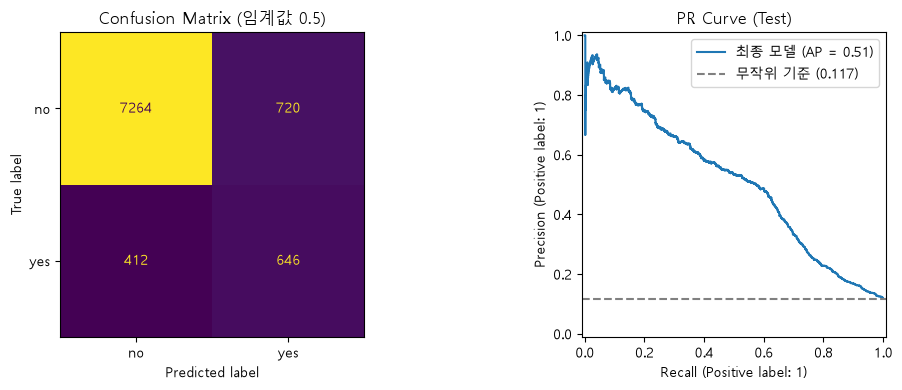

최종 모델 클래스 가중치: {0: 1, 1: np.float64(3.7741668636256205)}


In [ ]:
# 최종 학습 (Train 전체) → Test 한 번 평가
final_model.fit(X_train, y_train)
test_proba = final_model.predict_proba(X_test)[:, 1]

rows = []
for name, th in [('최종 (0.5)', THRESHOLD), ('참고 (F1 최적)', best_thr)]:
    pred = (test_proba >= th).astype(int)
    rows.append({'임계값 기준': name, '임계값': round(th, 3), 'PR-AUC': average_precision_score(y_test, test_proba),
                 'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred), 'Accuracy': accuracy_score(y_test, pred)})
display(pd.DataFrame(rows).set_index('임계값 기준').round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (test_proba >= THRESHOLD).astype(int),
                                        display_labels=['no', 'yes'], ax=ax[0], colorbar=False)
ax[0].set_title(f'Confusion Matrix (임계값 {THRESHOLD})')
PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=ax[1], name='최종 모델')
ax[1].axhline(y_test.mean(), ls='--', c='gray', label=f'무작위 기준 ({y_test.mean():.3f})')
ax[1].legend(); ax[1].set_title('PR Curve (Test)')
plt.tight_layout(); plt.show()

print('최종 모델 클래스 가중치:', final_model.named_steps['model'].get_params()['class_weight'])

> **결과 요약**
>
> | 지표 | Train 5-fold | **Test (임계값 0.5)** |
> | --- | --- | --- |
> | PR-AUC | 0.4869 | **0.5097** (무작위 0.117) |
> | F1 | 0.5174 | **0.5330** |
> | Recall | 0.5845 | **0.6106** |
> | Precision | 0.4642 | **0.4729** |
>
> - 혼동행렬: TN 7,264 · FP 720 · FN 412 · **TP 646** → 가입자 1,058명 중 **646명(61.1%)** 확보
> - 모델이 고른 1,366명의 실제 가입률 **47.3%** = 전체 가입률(11.7%)의 약 **4배**, 가입 1건당 통화 8.5통 → **2.1통**
> - F1 최적 임계값(0.497)의 Test 결과는 F1 0.5323으로 거의 같습니다 (헛걸음 3건 차이).

## 14. 중복 행 영향 확인 (진단용)

`duration` 제외 중복을 유지했기 때문에, Train에도 같은 행이 있는 Test 행이 결과를 부풀렸는지 확인합니다.  
진단용이라 이 결과로 모델이나 임계값을 바꾸지 않습니다.

In [ ]:
key = [c for c in X_train.columns if c != 'call_date']
tr_keys = X_train[key].astype(str).apply(tuple, axis=1)
te_keys = X_test[key].astype(str).apply(tuple, axis=1)
in_train = te_keys.isin(set(tr_keys)).values
tr_dup = tr_keys.isin(set(te_keys[in_train])).values
print('Train에도 같은 행이 있는 Test 행:', in_train.sum(), '/ Train 쪽 짝 행:', tr_dup.sum())

m2 = clone(final_model).fit(X_train[~tr_dup], y_train[~tr_dup])      # 짝을 본 적 없는 모델
proba2 = m2.predict_proba(X_test)[:, 1]

rows = []
for name, pr, mask in [('기존 모델 · 전체 Test', test_proba, np.ones(len(X_test), bool)),
                       ('기존 모델 · 중복 행 제외', test_proba, ~in_train),
                       ('짝 제외 학습 · 전체 Test', proba2, np.ones(len(X_test), bool))]:
    yt, pp = y_test.values[mask], pr[mask]
    pred = (pp >= THRESHOLD).astype(int)
    rows.append({'구분': name, '행 수': mask.sum(), 'PR-AUC': average_precision_score(yt, pp),
                 'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred), 'F1': f1_score(yt, pred),
                 '중복 행 예측확률(최대)': pr[in_train].max()})
display(pd.DataFrame(rows).set_index('구분').round(4))

Train에도 같은 행이 있는 Test 행: 5 / Train 쪽 짝 행: 6


,행 수,PR-AUC,Precision,Recall,F1,중복 행 예측확률(최대)
구분,,,,,,
기존 모델 · 전체 Test,9042,0.5097,0.4729,0.6106,0.5330,0.1856
기존 모델 · 중복 행 제외,9037,0.5097,0.4729,0.6106,0.5330,0.1856
짝 제외 학습 · 전체 Test,9042,0.5090,0.4729,0.6096,0.5326,0.1950


> **결과 요약:** Train과 같은 Test 행은 5행(모두 no)이었습니다.  
빼고 평가해도 지표가 같았고, 짝을 빼고 다시 학습해도 그 5행의 예측 확률은 0.2 미만이었습니다(0.186 → 0.195).  
따라서 **중복으로 인한 누수 영향은 미미했습니다.** 원칙적으로는 분할 전 제거가 더 안전합니다.

## 15. 모델 해석 (SHAP)

SHAP은 각 예측에서 피처가 확률을 **얼마나, 어느 방향으로** 움직였는지 보여줍니다. 값의 단위는 log-odds라 크기 비교와 방향만 봅니다.

c:\first-project\.venv\Lib\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


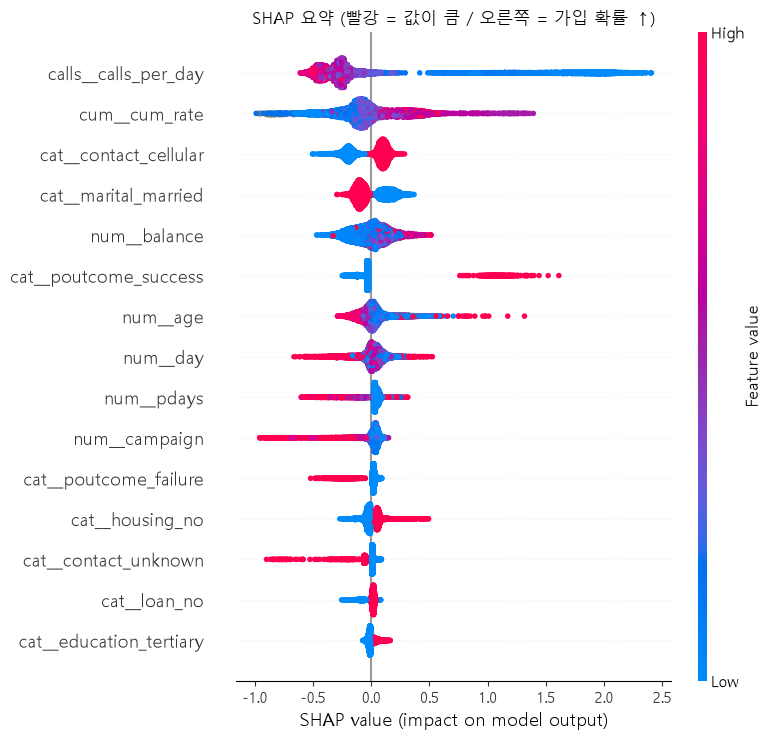

,평균 |SHAP|,"방향 (수치형만, + 가입↑ / − 가입↓)"
calls_per_day,0.531,-0.772
cum_rate,0.207,0.741
contact,0.177,NaN
poutcome,0.137,NaN
marital,0.136,NaN
balance,0.117,0.311
age,0.077,-0.315
day,0.076,-0.445
pdays,0.072,-0.758
month,0.062,NaN


In [ ]:
if RUN_SHAP:
    import shap
    prep  = final_model.named_steps['prep']
    model = final_model.named_steps['model']
    names = prep.get_feature_names_out()
    X_test_t = pd.DataFrame(prep.transform(X_test), columns=names, index=X_test.index)

    explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(X_test_t)
    if isinstance(sv, list):
        sv = sv[1]
    if sv.ndim == 3:
        sv = sv[:, :, 1]

    shap.summary_plot(sv, X_test_t, max_display=15, show=False)
    plt.title('SHAP 요약 (빨강 = 값이 큼 / 오른쪽 = 가입 확률 ↑)'); plt.tight_layout(); plt.show()

    # 원래 컬럼 단위로 합치기
    orig = [c for c in X_test.columns if c != 'call_date'] + ['calls_per_day', 'cum_rate']
    def to_orig(n):
        n = n.split('__', 1)[1]
        for c in sorted(orig, key=len, reverse=True):
            if n == c or n.startswith(c + '_'):
                return c
        return n
    col_map = [to_orig(n) for n in names]
    imp = pd.DataFrame(np.abs(sv), columns=col_map).T.groupby(level=0).sum().T.mean()
    direction = {}
    for i, n in enumerate(names):
        c = col_map[i]
        if not n.startswith('cat__') and c not in direction:
            x = X_test_t.iloc[:, i]; ok = x.notna().values
            direction[c] = np.corrcoef(x[ok], sv[ok, i])[0, 1]
    display(pd.DataFrame({'평균 |SHAP|': imp, '방향 (수치형만, + 가입↑ / − 가입↓)': pd.Series(direction)})
              .sort_values('평균 |SHAP|', ascending=False).round(3))

> **결과 요약**
> - **calls_per_day**(0.531)가 압도적 1위: 통화량이 많은 날일수록 가입 확률을 **낮춤**
> - **cum_rate**(0.207) 2위: 캠페인 후반일수록 가입 확률을 **높임**
> - 그다음 contact(0.177), marital(0.136), balance(0.117, 클수록 ↑), campaign(클수록 ↓) 순
> - age와 pdays는 관계가 직선이 아니라서(나이는 U자형) 방향 숫자보다 점 그림으로 해석해야 합니다.

## 16. 결론

| 항목 | 내용 |
| --- | --- |
| 최종 모델 | LightGBM (lr 0.01, 500그루, num_leaves 62, min_child_samples 25, 가중치 1:2) |
| 입력 | 원본 15개 컬럼 (duration 제외) + 하루 통화량 + 누적 가입률 |
| 임계값 | 0.5 |
| Test 성능 | PR-AUC 0.510 · F1 0.533 · Recall 0.611 · Precision 0.473 |
| 비즈니스 효과 | 전화를 85% 줄이고 가입자의 61%를 확보. 가입 1건당 통화 8.5통 → 2.1통 |

**배운 점**
1. 불균형 처리(가중치 · RUS · SMOTE)는 PR-AUC를 올리지 못하고, Precision과 Recall의 균형만 바꿨습니다.
2. 성능을 가장 크게 올린 것은 모델이나 튜닝이 아니라 **데이터에 없던 정보를 만든 파생변수**(하루 통화량)였습니다.
3. 놓친 가입자의 대부분은 2008년 대량 통화일에 있었습니다. 이 구간의 가입자는 비가입자와 특징이 거의 같아 구별이 어렵습니다 (추가 분석).

**한계**
- 고객 ID가 없어 같은 고객의 반복 등장을 확정할 수 없습니다.